# Reajuste químico natural: theta_new

Esta versión sustituye la calibración theta_new descartada. Se parte del **theta_full natural anterior** y se reajustan exclusivamente sus once parámetros libres con **LAB004–009 depurados**, excluyendo LAB010–012. Los seis parámetros sN, qXG, qXF, sG, sF y m0 permanecen exactamente iguales a theta_full. No se realiza ninguna optimización conjunta con sintéticos ni se reutilizan los parámetros de la versión theta_new descartada.

Se mantienen ecuaciones, siete estados, cotas, ponderaciones y objetivo histórico del reajuste natural (sin penalización L2 adicional). Cuatro arranques: theta_full y tres perturbaciones lognormales del bloque libre (σ=0.65, semilla 90610). Los seis valores fijos no se perturban. Las observaciones corregidas/depuradas, pulso real y logs filtrados se verifican en las celdas siguientes.

Los sintéticos MS007–016 se conservan **solo para evaluar transferencia**, sin participar en la optimización ni en la selección del ajuste. El holdout LAB019–021 mantiene las condiciones iniciales corregidas acordadas en v3. Se conservan todos los resultados históricos, incluido multistart_07. SOURCE y EXECUTED son autocontenidos; no se crean auxiliares Python, CSV ni figuras externas en results. Los archivos de la versión theta_new descartada se reemplazan por los de este reajuste.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from dataclasses import replace
import sys, json, hashlib, time, re, os
from concurrent.futures import ProcessPoolExecutor, as_completed
# Los hijos heredan el entorno Conda activado. Evitar sobreasignación de BLAS entre procesos.
for _key in ["OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS"]:os.environ[_key]="1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from IPython import get_ipython
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib','inline')
ROOT=next(p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents] if (p/'fermentation_model/shared').is_dir())
FM=ROOT/'fermentation_model'
if str(FM) not in sys.path:sys.path.insert(0,str(FM))
from shared import run_new_must_glycerol_estimability_doe as model
OUT=FM/'laboratory_2026/notebooks/calibration/theta_new'
LABS=tuple(f'LAB{i:03}' for i in range(4,10))
MS=tuple(f'MS{i:03}' for i in range(7,17))
PARAMS=tuple(model.FULL17); FREE11=tuple(model.REDUCED11)
FIXED6=tuple(p for p in PARAMS if p not in FREE11)
L2_PARAMS=tuple(p for p in PARAMS if p not in model.CORE_FIT)
CONFIG={'seed':90609,'sigma':.65,'calibration_mode':'natural11_from_historical_theta_full','natural_starts':4,
        'max_nfev':200,'workers':3,'natural_l2_lambda':0.,'temperature_grid_h':2.,
        'filter':{'median_min':30,'rolling_bins':3,'cutoff_period_h':4.,'order':2,'max_gap_h':.500001}}
INPUTS={
 'chemistry':FM/'shared/results/secondary_metabolite_data_review/secondary_metabolite_long.csv',
 'natural_book':FM/'data/Laboratorio 2026/Vendimia_2026/mosto_natural_xthiol.xlsx',
 'clock':FM/'laboratory_2026/results/estimability_historical_natural/process_temperature_30min.csv',
 'initial_reference':FM/'laboratory_2026/results/estimability_historical_natural/theta_natural_full.csv',
 'model':Path(model.__file__),
}
def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
# Proteger los resultados anteriores y las fuentes; ninguna rutina de ajuste histórica se invoca como runner.
protected_roots=[FM/'shared/results/new_must_glycerol_overnight_validation',
                 FM/'shared/results/new_must_glycerol_estimability_doe',
                 FM/'laboratory_2026/results/estimability_historical_natural',
                 FM/'laboratory_2026/results/estimability_historical_synthetic']
protected={str(p.relative_to(ROOT)):sha(p) for root in protected_roots if root.exists() for p in root.rglob('*') if p.is_file()}
old_full=pd.read_csv(FM/'laboratory_2026/results/estimability_historical_natural/theta_natural_full.csv').set_index('parameter').theta.astype(float).to_dict()
old_defaults={**old_full,**{k:float(model.DEFAULT_THETA[k]) for k in FIXED6}}
old_ms07=pd.read_csv(FM/'shared/results/new_must_glycerol_overnight_validation/theta_multistart_07.csv',index_col=0).iloc[:,0].astype(float).to_dict()
reference=dict(old_full)
assert set(reference)==set(PARAMS) and len(FIXED6)==6 and len(FREE11)==11
assert reference==old_full
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':110,'font.size':9})
print('Entorno:',sys.executable,'; se preservan',len(protected),'archivos históricos')
pd.set_option('display.max_rows',200)

Entorno: D:\anaconda3\envs\fermentation\python.exe ; se preservan 231 archivos históricos


## 1. Datos depurados y pulsos

Los faltantes de una variable no eliminan las otras observaciones de la fila. Las seis exclusiones Oculyze y las tres correcciones manuales se verifican contra la tabla normalizada. Se conservan las conversiones y cotas inferiores históricas; los negativos originales y las condiciones iniciales posteriores al inicio se auditan, no se ocultan.

**Nutrición natural:** se lee la columna `pulso real` del Excel (68.5, 68.5, 100, 65.5, 65.5 y 41.846153846 h), aplicando 80 mg N/L. La antigua fila del pulso no aporta una observación química adicional ni otro pulso: se sustituye el horario del evento, sin desplazar muestras. **Sintéticos (solo evaluación, nunca ajuste):** 100 mg N/L a los horarios tabulados (24, 72 o 96 h). Son entradas aceptadas para esta calibración, no dosis verificadas a partir de activaciones de bomba. No se añaden pulsos por cada activación del log.

Se mantienen condiciones iniciales a partir de la primera observación finita y los valores predeterminados históricos cuando toda una especie carece de mediciones. La convención en una muestra coincidente con una adición es muestra antes de la acción. Los errores principales de comparación excluyen las observaciones utilizadas como condición inicial; el objetivo de optimización conserva la definición histórica.

In [2]:
d=pd.read_csv(INPUTS['chemistry'])
d=d[((d.medium=='natural')&d.batch.isin(LABS))|((d.medium=='synthetic')&d.batch.isin(MS))].copy()
assert set(d.batch)==set(LABS+MS) and not d.duplicated(['medium','batch','time_h']).any()
negative_audit=[]
for state,col in model.STATE_COLUMNS.items():
    d[col]=pd.to_numeric(d[col],errors='coerce')
    for lab,g in d.groupby('batch'):
        negative_audit.append({'batch':lab,'state':state,'n_negative':int(g[col].lt(0).sum())})
    d.loc[d[col]<0,col]=0. # regla histórica de preparación de los siete estados
for lab,expected in [('LAB004',1.044),('LAB005',1.5576),('LAB006',.9195)]:
    assert np.isclose(d.loc[d.batch.eq(lab)&d.sample_id.eq(f'ING26-{lab}-04'),'X_viable_kg_m3'].iloc[0],expected)
excluded=[('LAB004','ING26-LAB004-10'),('LAB005','ING26-LAB005-10'),('LAB006','ING26-LAB006-09'),
          ('LAB007','ING26-LAB007-L-13'),('LAB008','ING26-LAB008-L-13'),('LAB009','ING26-LAB009-L-12')]
for lab,sample in excluded:
    r=d.loc[d.batch.eq(lab)&d.sample_id.eq(sample)]
    assert len(r)==1 and r[['X_viable_kg_m3','X_dead_kg_m3']].isna().all().all()
base_batches=model.make_batches(d)
assert len(base_batches)==16
natural_pulses={}
for lab in LABS:
    sheet=pd.read_excel(INPUTS['natural_book'],sheet_name=lab,usecols=['t','pulso_nut','pulso real'])
    pulse=sheet.loc[sheet['pulso real'].notna()]
    assert len(pulse)==1 and np.isclose(pulse.pulso_nut.iloc[0],80.)
    natural_pulses[lab]=float(pulse['pulso real'].iloc[0])
assert np.allclose(list(natural_pulses.values()),[68.5,68.5,100,65.5,65.5,41.84615384615385])
clocks=pd.read_csv(INPUTS['clock'],usecols=['batch','t0']).drop_duplicates().set_index('batch').t0
assert clocks.index.is_unique
original_times={b.batch:b.time.copy() for b in base_batches}
initial_audit=[]
for b in base_batches:
    group=d[d.batch.eq(b.batch)].sort_values('time_h')
    for state,col in model.STATE_COLUMNS.items():
        finite=group.dropna(subset=[col])
        initial_audit.append({'batch':b.batch,'state':state,'initial':b.initials[state],
            'source_time_h':float(finite.time_h.iloc[0]) if len(finite) else np.nan,
            'fallback':not len(finite)})
initial_audit=pd.DataFrame(initial_audit)
negative_audit=pd.DataFrame(negative_audit)
display(negative_audit.groupby('state').n_negative.sum().rename('negativos_llevados_a_cero').to_frame())
display(initial_audit[initial_audit.source_time_h.gt(0)|initial_audit.fallback])

,negativos_llevados_a_cero
state,
E,0
F,3
G,0
Gly,0
N,0
X,0
Xd,0


,batch,state,initial,source_time_h,fallback
42,MS007,X,0.33300,3.5,False
49,MS008,X,0.32835,3.5,False
56,MS009,X,0.33750,3.5,False
63,MS010,X,0.56100,3.0,False
70,MS011,X,0.36975,3.0,False
77,MS012,X,0.47580,3.0,False
84,MS013,X,0.45975,22.0,False
91,MS014,X,0.48495,22.0,False
98,MS015,X,0.38130,22.0,False
105,MS016,X,0.49080,17.0,False


## 2. Temperatura utilizada

En naturales se reconstruyen los logs crudos completos, uniendo fragmentos y comprobando duplicados. Se aplica el filtro de `preparing_data`: medianas de 30 minutos, mediana móvil centrada de 90 minutos y Butterworth de orden 2 con período de corte de 4 h, sin desfase. No se filtra a través de intervalos sin registros ni cambios de consigna. Entre resúmenes térmicos se interpola linealmente; las extensiones inicial/final usan la lectura filtrada más cercana, sin recurrir al Excel. Los huecos interiores de los logs se auditan explícitamente.

La representación para integrar usa la malla histórica de 2 h, más tiempos químicos y puntos térmicos alrededor de los cambios de consigna. LAB009 recibe el perfil registrado 21→18 °C. Para evaluar sintéticos se conserva la temperatura operacional tabulada, con el tratamiento histórico de faltantes; no se inventan logs continuos ni se sustituye por las escasas temperaturas medidas.

In [3]:
profiles={}; thermal_audit=[]; log_inventory=[]
for lab in LABS:
    paths=sorted(p for p in (FM/'data/Laboratorio 2026/raw_data').rglob('*.csv')
        if p.name.lower().startswith('temp') and re.search(rf'lab0*{int(lab[3:])}(?:\D|$)',p.name,re.I))
    assert paths,lab
    fragments=[]
    for p in paths:
        INPUTS[f'log_{lab}_{len(fragments)}']=p
        part=pd.read_csv(p,usecols=['timestamp','T','SP'])
        part['timestamp']=pd.to_datetime(part.timestamp,errors='coerce')
        for col in ['T','SP']:part[col]=pd.to_numeric(part[col],errors='coerce')
        fragments.append(part.dropna(subset=['timestamp']))
        log_inventory.append({'batch':lab,'path':str(p.relative_to(ROOT)),'rows':len(part)})
    raw=pd.concat(fragments).sort_values('timestamp',kind='stable')
    dup=raw[raw.timestamp.duplicated(keep=False)]
    if len(dup):assert dup.groupby('timestamp')[['T','SP']].nunique().le(1).all().all()
    raw=raw.drop_duplicates('timestamp');t0=pd.Timestamp(clocks[lab])
    raw['t_h']=(raw.timestamp-t0).dt.total_seconds()/3600
    raw=raw[raw.t_h.ge(0)].dropna(subset=['T'])
    profile=raw.set_index('timestamp')[['T','SP']].resample('30min').median().dropna(subset=['T']).reset_index()
    profile['t_h']=(profile.timestamp-t0).dt.total_seconds()/3600+.25
    profile=profile[profile.t_h.between(0,raw.t_h.max())].copy()
    gap=profile.t_h.diff().gt(CONFIG['filter']['max_gap_h'])
    step=profile.SP.diff().abs().gt(.5)
    profile['segment']=(gap|step).cumsum();profile['filtered']=np.nan
    sos=butter(2,1/4.,fs=2.,output='sos')
    for seg,g in profile.groupby('segment'):
        smooth=g['T'].rolling(3,center=True,min_periods=1).median().to_numpy()
        profile.loc[g.index,'filtered']=sosfiltfilt(sos,smooth) if len(smooth)>9 else smooth
    assert np.isfinite(profile.filtered).all()
    # Los huecos interiores de la señal densa se muestran en la auditoría, no se confunden con nutrición.
    gaps=[]
    for i in np.flatnonzero(gap.to_numpy()):
        left=profile.iloc[i-1].t_h;right=profile.iloc[i].t_h
        gaps.append([float(left),float(right)])
    profiles[lab]=profile
    horizon=max(original_times[lab])
    thermal_audit.append({'batch':lab,'sensor_start_h':profile.t_h.min(),'sensor_end_h':profile.t_h.max(),
        'extension_initial_h':max(0.,profile.t_h.min()),'extension_final_h':max(0.,horizon-profile.t_h.max()),
        'interior_gaps_h':gaps,'SP_changes_h':profile.loc[step,'t_h'].tolist()})
display(pd.DataFrame(thermal_audit))
display(pd.DataFrame(log_inventory))
batches=[]
for old in base_batches:
    pulses=dict(old.pulses)
    if old.medium=='natural':
        pulses['N']=((natural_pulses[old.batch],.08),)
        profile=profiles[old.batch];horizon=float(old.time[-1])
        knots=np.arange(0,horizon+1e-9,CONFIG['temperature_grid_h'])
        # Incluir ambos lados del cambio filtrado conserva su rapidez sin suavizarlo sobre 2 h.
        switches=profile.loc[profile.segment.diff().fillna(0).ne(0),'t_h'].to_numpy()
        knots=np.r_[knots,switches,switches-.5]
        grid=np.unique(np.r_[old.time,knots[(knots>=0)&(knots<=horizon)]])
        temperature=np.interp(grid,profile.t_h,profile.filtered)
        observations={s:np.full(len(grid),np.nan) for s in model.STATE_NAMES}
        idx=np.searchsorted(grid,old.time)
        for state in model.STATE_NAMES:observations[state][idx]=old.observations[state]
        batch=replace(old,time=grid,temperature_c=temperature,pulses=pulses,observations=observations)
    else:
        assert len(pulses['N'])==1 and np.isclose(pulses['N'][0][1],.1)
        batch=old
    batches.append(batch)
natural=[b for b in batches if b.medium=='natural']
assert len(natural)==6 and len(batches)==16
for old,new in zip(base_batches,batches):
    for s in model.STATE_NAMES:
        assert np.array_equal(old.observations[s],new.observations[s][np.searchsorted(new.time,old.time)],equal_nan=True)
    assert new.initials==old.initials
pulse_table=pd.DataFrame([{'batch':b.batch,'medium':b.medium,'pulse_h':b.pulses['N'][0][0],
    'dose_mg_N_L':b.pulses['N'][0][1]*1000,'n_observations':sum(np.isfinite(v).sum() for v in b.observations.values())} for b in batches])
display(pulse_table)
INPUT_HASHES={k:sha(p) for k,p in INPUTS.items()}
signature=hashlib.sha256(json.dumps({'inputs':INPUT_HASHES,'config':CONFIG},sort_keys=True).encode()).hexdigest()
CHECKPOINT=OUT/'fit_checkpoint.json'
checkpoint={'signature':signature,'config':CONFIG,'natural':[]}
if CHECKPOINT.exists():
    checkpoint=json.loads(CHECKPOINT.read_text(encoding='utf-8'))
    assert checkpoint['signature']==signature,'Entradas cambiaron: no reutilizar ajustes de otra configuración'
def save_checkpoint():
    tmp=CHECKPOINT.with_suffix('.tmp');tmp.write_text(json.dumps(checkpoint,indent=2,ensure_ascii=False),encoding='utf-8');tmp.replace(CHECKPOINT)
start=time.perf_counter();baseline=model.residual_vector(reference,natural)
assert np.isfinite(baseline).all() and len(baseline)>100
print('Benchmark:',round(time.perf_counter()-start,3),'s por evaluación;',len(baseline),'residuos medidos')

,batch,sensor_start_h,sensor_end_h,extension_initial_h,extension_final_h,interior_gaps_h,SP_changes_h
0,LAB004,1.75,190.25,1.75,0.0,"[[18.25, 19.25]]","[99.25, 171.25]"
1,LAB005,1.75,190.25,1.75,0.0,"[[18.25, 19.25]]","[99.25, 171.25]"
2,LAB006,1.75,213.25,1.75,0.0,"[[18.25, 19.25]]",[123.25]
3,LAB007,0.25,161.25,0.25,0.0,[],[92.25]
4,LAB008,0.25,161.25,0.25,0.0,[],[92.25]
5,LAB009,0.25,161.25,0.25,0.0,[],[68.25]


,batch,path,rows
0,LAB004,fermentation_model\data\Laboratorio 2026\raw_d...,17346
1,LAB004,fermentation_model\data\Laboratorio 2026\raw_d...,179381
2,LAB005,fermentation_model\data\Laboratorio 2026\raw_d...,17333
3,LAB005,fermentation_model\data\Laboratorio 2026\raw_d...,179382
4,LAB006,fermentation_model\data\Laboratorio 2026\raw_d...,17325
5,LAB006,fermentation_model\data\Laboratorio 2026\raw_d...,203070
6,LAB007,fermentation_model\data\Laboratorio 2026\raw_d...,148435
7,LAB008,fermentation_model\data\Laboratorio 2026\raw_d...,148426
8,LAB009,fermentation_model\data\Laboratorio 2026\raw_d...,148421


,batch,medium,pulse_h,dose_mg_N_L,n_observations
0,LAB004,natural,68.500000,80.0,79
1,LAB005,natural,68.500000,80.0,79
2,LAB006,natural,100.000000,80.0,91
3,LAB007,natural,65.500000,80.0,82
4,LAB008,natural,65.500000,80.0,82
5,LAB009,natural,41.846154,80.0,75
6,MS007,synthetic,24.000000,100.0,57
7,MS008,synthetic,96.000000,100.0,56
8,MS009,synthetic,24.000000,100.0,57
9,MS010,synthetic,24.000000,100.0,56


Benchmark: 0.362 s por evaluación; 488 residuos medidos


## 3. Referencia histórica y definición de los arranques

La inicialización es theta_full anterior, leído de theta_natural_full.csv. Se preservan sus seis valores fijos. Solo se perturban los once parámetros libres para explorar soluciones del reajuste natural. Se conserva el objetivo histórico sin L2 adicional, junto a cotas y tolerancias del modelo compartido. Se registran convergencia y dispersión; una parada exitosa no demuestra identificabilidad.

El checkpoint corresponde exclusivamente a estas entradas, referencia y configuración. No admite ajustes de la versión descartada. La columna seconds incluye la espera en cola.

In [4]:
def random_start(center,rng,parameters):
    theta=dict(center)
    for p in parameters:theta[p]=theta[p]*np.exp(rng.normal(0,CONFIG['sigma']))
    return model.clip_theta(theta)
def fit_stage(stage,fit_batches,center,free,nstarts,seed,l2):
    rng=np.random.default_rng(seed)
    starts=[dict(center)]+[random_start(center,rng,free) for _ in range(nstarts-1)]
    done=checkpoint[stage]
    indexed={int(r['summary']['fit'].rsplit('_',1)[1])-1:r for r in done}
    for i,r in indexed.items():
        assert all(np.isclose(starts[i][p],r['initial'][p]) for p in PARAMS)
    with ProcessPoolExecutor(max_workers=CONFIG['workers']) as executor:
        futures={}
        for i,initial in enumerate(starts):
            if i in indexed:continue
            t=time.perf_counter()
            print(f'{stage} {i+1}/{nstarts}: programado ({len(free)} parámetros)',flush=True)
            future=executor.submit(model.fit_parameters,f'{stage}_{i+1:02}',fit_batches,initial,free,
                max_nfev=CONFIG['max_nfev'],l2_reference=reference if l2 else None,
                l2_parameters=L2_PARAMS if l2 else (),l2_lambda=l2)
            futures[future]=(i,initial,t)
        for future in as_completed(futures):
            i,initial,t=futures[future]
            theta,summary=future.result()
            residual=model.residual_vector(theta,fit_batches)
            data_wsse=float(residual@residual)
            penalty=float(l2*sum(np.log(theta[p]/reference[p])**2 for p in L2_PARAMS))
            assert np.isclose(summary['final_wsse'],data_wsse+penalty)
            record={'initial':initial,'theta':theta,'summary':{**summary,'data_wsse':data_wsse,
                'penalty':penalty,'seconds':time.perf_counter()-t}}
            indexed[i]=record
            checkpoint[stage]=[indexed[j] for j in sorted(indexed)]
            save_checkpoint()
            print(f"Terminado {summary['fit']}: objetivo={summary['final_wsse']:.3f}, datos={data_wsse:.3f}, nfev={summary['nfev']}, éxito={summary['success']}",flush=True)
    done=checkpoint[stage]
    assert len(done)==nstarts
    converged=[r for r in done if r['summary']['success']]
    best=min(converged or done,key=lambda r:r['summary']['final_wsse'])
    return best,done
display(pd.DataFrame({'theta_full_inicial':pd.Series(reference),'rol':pd.Series({p:'fijo heredado' if p in FIXED6 else 'libre natural' for p in PARAMS})}))

,theta_full_inicial,rol
mu0,0.078728,libre natural
sN,8.751446,fijo heredado
qN,0.021080,libre natural
qXG,0.081491,fijo heredado
qXF,0.070933,fijo heredado
betaG0,0.428878,libre natural
sG,0.097455,fijo heredado
betaF0,3.440399,libre natural
sF,0.178295,fijo heredado
qEG,1.712807,libre natural


## 4. Reajuste de once parámetros con LAB004–009

Se parte de theta_full histórico. Se mantienen seis parámetros en sus valores históricos y se optimizan los once restantes únicamente con los seis LAB naturales depurados. Ningún sintético ni LAB019–021 participa en el objetivo o en la selección. No se reutiliza el theta_new descartado.

In [5]:
natural_best,natural_runs=fit_stage('natural',natural,reference,FREE11,CONFIG['natural_starts'],CONFIG['seed']+1,0.)
theta_new=dict(natural_best['theta'])
assert all(theta_new[p]==reference[p] for p in FIXED6)
assert all(r['theta'][p]==reference[p] for r in natural_runs for p in FIXED6)
display(pd.DataFrame([r['summary'] for r in natural_runs])[['fit','success','nfev','data_wsse','final_wsse','seconds']])
natural_spread=pd.DataFrame([r['theta'] for r in natural_runs])[list(FREE11)].agg(['min','max']).T
natural_spread['max_over_min']=natural_spread['max']/natural_spread['min']
display(natural_spread)

,fit,success,nfev,data_wsse,final_wsse,seconds
0,natural_01,True,21,2357.142392,2357.142392,140.755041
1,natural_02,True,19,2357.363439,2357.363439,131.401819
2,natural_03,True,18,2357.148663,2357.148663,123.831099
3,natural_04,True,25,2357.179875,2357.179875,215.163596


,min,max,max_over_min
mu0,0.083094,0.083102,1.000087
qN,0.016103,0.016116,1.000855
betaG0,0.555296,0.566703,1.020542
betaF0,0.283109,0.297627,1.051278
qEG,1.015522,1.039285,1.023401
qEF,0.695225,0.727213,1.046010
iG,0.003410,0.003941,1.155772
iE,0.008183,0.008985,1.098060
Kd0,0.000100,0.000100,1.000000
gammaG0,0.068990,0.070653,1.024115


## 5. Parámetros frente a los vectores anteriores

Se compara theta_new reajustado con theta_full histórico (también inicialización), theta_defaults y multistart_07. Los seis fijos permanecen iguales a theta_full. Los porcentajes son cambios de parámetros; no mejoras de predicción. Se marcan los parámetros próximos a cotas según distancia logarítmica menor del 1%.

,theta_new,theta_full,theta_defaults,multistart_07,etapa_final,change_pct_vs_theta_full,change_pct_vs_theta_defaults,change_pct_vs_multistart_07,lower,upper,near_bound
parameter,,,,,,,,,,,
mu0,0.0830971,0.0787279,0.0787279,0.0601697,reajustado natural,5.54967,5.54967,38.1044,0.05,1,
sN,8.75145,8.75145,18,8.75145,fijo de theta_full histórico,0,-51.3809,0,0.5,100,
qN,0.0161152,0.0210804,0.0210804,0.0146092,reajustado natural,-23.5536,-23.5536,10.3082,0.0005,1,
qXG,0.081491,0.081491,0.1125,0.081491,fijo de theta_full histórico,0,-27.5636,0,0.005,10,
qXF,0.0709327,0.0709327,0.1125,0.0709327,fijo de theta_full histórico,0,-36.9487,0,0.005,10,
betaG0,0.555296,0.428878,0.428878,0.779854,reajustado natural,29.4765,29.4765,-28.7948,0.1,10,
sG,0.0974551,0.0974551,0.03,0.0974551,fijo de theta_full histórico,0,224.85,0,0.01,1000,
betaF0,0.283109,3.4404,3.4404,0.510897,reajustado natural,-91.771,-91.771,-44.5858,0.1,10,
sF,0.178295,0.178295,0.03,0.178295,fijo de theta_full histórico,0,494.317,0,0.01,1000,


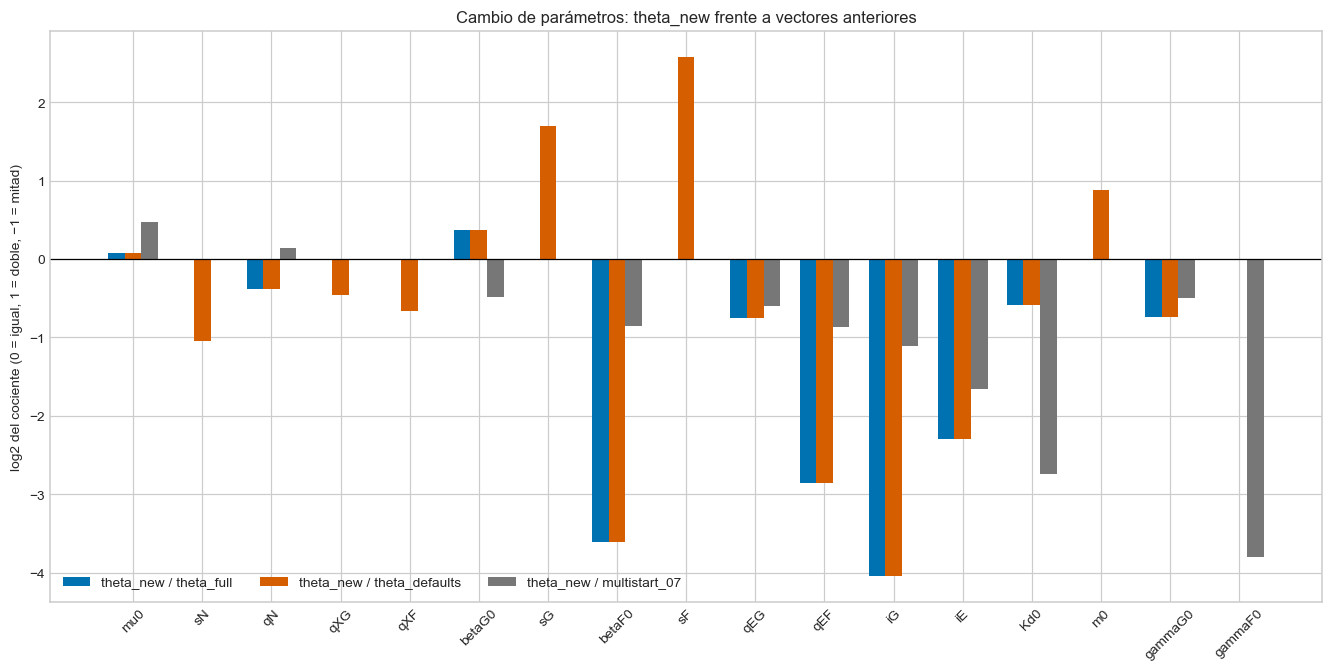

In [6]:
VECTORS={'theta_new':theta_new,'theta_full':old_full,
         'theta_defaults':old_defaults,'multistart_07':old_ms07}
comparison=pd.DataFrame(VECTORS).reindex(PARAMS)
comparison.index.name='parameter'
comparison['etapa_final']=np.where(comparison.index.isin(FIXED6),'fijo de theta_full histórico','reajustado natural')
for name in ['theta_full','theta_defaults','multistart_07']:
    comparison[f'change_pct_vs_{name}']=100*(comparison.theta_new/comparison[name]-1)
comparison['lower']=[model.PARAMETER_BOUNDS[p][0] for p in PARAMS]
comparison['upper']=[model.PARAMETER_BOUNDS[p][1] for p in PARAMS]
position=np.log(comparison.theta_new/comparison.lower)/np.log(comparison.upper/comparison.lower)
comparison['near_bound']=np.where(position<.01,'inferior',np.where(position>.99,'superior',''))
with pd.option_context('display.max_rows',30,'display.max_columns',12,'display.float_format',lambda x:f'{x:.6g}'):
    display(comparison)
fig,ax=plt.subplots(figsize=(12,6),layout='constrained')
x=np.arange(len(PARAMS));width=.24
for off,name,color in [(-1,'theta_full','#0072B2'),(0,'theta_defaults','#D55E00'),(1,'multistart_07','#777777')]:
    ax.bar(x+off*width,np.log2(comparison.theta_new/comparison[name]),width,label=f'theta_new / {name}',color=color)
ax.axhline(0,color='black',lw=.8)
ax.set(xticks=x,xticklabels=PARAMS,ylabel='log2 del cociente (0 = igual, 1 = doble, −1 = mitad)',title='Cambio de parámetros: theta_new frente a vectores anteriores')
ax.tick_params(axis='x',rotation=45);ax.legend(ncol=3,fontsize=9)
plt.show();plt.close(fig)

## 6. Errores químicos bajo las mismas entradas corregidas

Todos los vectores se evalúan con los mismos datos depurados, pulsos corregidos y temperaturas nuevas. Esta comparación no reproduce las métricas publicadas antiguas, que usaban otras entradas. LAB004–009 son experimentos de ajuste; MS007–016 son únicamente evaluación de transferencia y no participan en este reajuste. Se muestra RMSE por variable y experimento, junto a WRMSE con las ponderaciones históricas. Los errores físicos de YAN se expresan en mg N/L.

In [7]:
metrics=[];predictions={};numeric=[]
for label,theta in VECTORS.items():
    predictions[label]={}
    for b in batches:
        times=original_times[b.batch]
        sim=model.simulate(b,theta,times)
        assert sim is not None and np.isfinite(sim.to_numpy()).all(),(label,b.batch)
        predictions[label][b.batch]=sim
        ix=np.searchsorted(b.time,times)
        for state in model.STATE_NAMES:
            obs=b.observations[state][ix];finite=np.isfinite(obs)
            anchor=initial_audit[(initial_audit.batch==b.batch)&(initial_audit.state==state)].source_time_h.iloc[0]
            mask=finite & ~np.isclose(times,anchor,atol=1e-9,rtol=0)
            if not mask.any():continue
            err=sim[state].to_numpy()[mask]-obs[mask]
            factor=1000 if state=='N' else 1
            sigma=model.sigma_for_state(state,obs[mask])
            metrics.append({'theta':label,'medium':b.medium,'batch':b.batch,'state':state,'n':int(mask.sum()),
                'RMSE':float(np.sqrt(np.mean(err**2))*factor),'bias':float(err.mean()*factor),
                'WRMSE':float(np.sqrt(np.mean((err/sigma)**2))),'weighted_SSE':float(np.sum((err/sigma)**2))})
        if label=='theta_new':
            fine=model.simulate(b,theta,times,integration_max_step_h=.5)
            assert fine is not None
            for state in model.STATE_NAMES:
                diff=fine[state].to_numpy()-sim[state].to_numpy()
                numeric.append({'batch':b.batch,'state':state,'max_abs_delta':float(abs(diff).max()),
                    'max_delta_sigma':float(np.max(abs(diff)/model.sigma_for_state(state,sim[state].to_numpy())))})
metrics=pd.DataFrame(metrics);numeric=pd.DataFrame(numeric)
summary=metrics.groupby(['theta','medium']).agg(weighted_SSE=('weighted_SSE','sum'),n=('n','sum'))
summary['WRMSE']=np.sqrt(summary.weighted_SSE/summary.n)
display(summary)
print('RMSE por variable y experimento (entradas iniciales excluidas):')
for medium in ['natural','synthetic']:
    print(medium)
    display(metrics[(metrics.medium==medium)&metrics.theta.isin(['theta_new','theta_full','theta_defaults','multistart_07'])]
            .pivot(index=['batch','state'],columns='theta',values='RMSE').round(4))
print('Comprobación de integración 2 h frente a 0.5 h:')
display(numeric.groupby('state')[['max_abs_delta','max_delta_sigma']].max())
variable_metrics=metrics.assign(physical_SSE=metrics.RMSE**2*metrics.n).groupby(['theta','medium','state']).agg(physical_SSE=('physical_SSE','sum'),n=('n','sum'))
variable_metrics['RMSE']=np.sqrt(variable_metrics.physical_SSE/variable_metrics.n)
print('RMSE agregado por variable en naturales:')
display(variable_metrics.xs('natural',level='medium').RMSE.unstack('theta').round(4))

weighted_SSE    n     WRMSE
theta          medium                                
multistart_07  natural     4191.094605  446  3.065465
               synthetic  10923.987793  472  4.810825
theta_defaults natural    10950.523744  446  4.955073
               synthetic  19033.396550  472  6.350196
theta_full     natural     3807.797816  446  2.921928
               synthetic  13625.283368  472  5.372814
theta_new      natural     2357.180864  446  2.298947
               synthetic  17697.629647  472  6.123314

RMSE por variable y experimento (entradas iniciales excluidas):
natural


theta         multistart_07  theta_defaults  theta_full  theta_new
batch  state                                                      
LAB004 E             7.4530         19.3979      7.4352     6.5119
       F             6.4801         16.1140      6.2932     8.9751
       G             3.7887          5.4849      4.8875     5.3242
       Gly           0.6247          0.5843      0.4597     0.3810
       N            25.3843         43.2992     41.2605    32.6372
       X             0.3311          0.4001      0.4030     0.2294
       Xd            0.0371          0.0217      0.0223     0.0214
LAB005 E             4.0794         12.6503      3.7414     8.4901
       F             7.1832         23.4299      4.8756     3.3826
       G             3.4907          4.7199      4.5918     6.3442
       Gly           1.8834          1.8726      1.8427     1.8912
       N            34.9421         58.9674     55.8239    43.7120
       X             0.2805          0.3800      0.3800     0.2522
       Xd            0.0655          0.0191      0.0261     0.0248
LAB006 E            15.3247         26.7188     17.0047     4.9111
       F            13.2754         24.5384     12.1945     5.5022
       G            17.7086         15.3632     14.1789    10.7874
       Gly           1.1282          0.8762      0.8294     0.6919
       N            50.3701         31.1179     31.1445    34.4961
       X             0.8058          0.7571      0.7653     0.5794
       Xd            0.0526          0.0521      0.0523     0.0539
LAB007 E             5.5277         18.0267      6.7754     2.1950
       F             7.2715         22.0905      6.5183     3.5181
       G             5.9614          7.3879      5.2046     1.7117
       Gly           0.6898          0.5951      0.4842     0.4546
       N            18.0260         32.4555     30.7689    23.4160
       X             0.2560          0.2892      0.2925     0.1374
       Xd            0.0111          0.0117      0.0096     0.0064
LAB008 E             8.1233         19.9485      8.5054     3.4076
       F             8.0981         22.2857      6.6238     3.2486
       G             6.3214          7.0919      5.0865     1.7447
       Gly           0.7289          0.5955      0.4956     0.4806
       N            21.6205         28.0925     25.2590    19.9706
       X             0.3570          0.3709      0.3748     0.1742
       Xd            0.0115          0.0130      0.0119     0.0092
LAB009 E             5.2106         16.9953      5.6607     1.3821
       F             5.7121         21.0576      4.7153     3.8945
       G             5.1780          6.8140      4.6856     2.2958
       Gly           0.8847          0.8233      0.6760     0.6169
       N            23.4383         40.3076     37.8354    29.6515
       X             0.1709          0.2572      0.2569     0.1868
       Xd            0.0167          0.0208      0.0182     0.0164

synthetic


theta        multistart_07  theta_defaults  theta_full  theta_new
batch state                                                      
MS007 E            14.0357          6.5514     10.9680    31.3855
      F             7.0940          5.4213     12.7451    23.1731
      G            14.0378         18.4698     19.4499    20.5851
      Gly           0.8261          1.2456      1.3590     1.5110
      N           156.2895        182.4482    180.7223   171.1223
      X             0.2171          0.2788      0.2673     0.5652
      Xd            0.5990          0.6162      0.6139     0.6031
MS008 E            11.0063         10.8124      3.7380    26.6917
      F             6.6127         15.2201      8.7131    14.7638
      G             9.0001         11.9433     12.7045    13.7688
      Gly           0.6364          1.0333      1.1460     1.3767
      N           102.3186        122.9344    122.3053   113.1173
      X             0.2012          0.2845      0.2830     0.2827
      Xd            0.4960          0.5085      0.5075     0.4975
MS009 E             9.9140         29.2705     11.1633     1.4450
      F            10.4399         27.6694      9.5003     6.1685
      G            14.7988         12.7802     11.6638    11.0879
      Gly           1.2483          1.1182      1.1283     1.3346
      N            41.3945         63.1697     59.3495    49.1984
      X             0.2819          0.3326      0.2825     0.4158
      Xd            0.5408          0.7796      0.7115     0.6784
MS010 E             4.2016         20.3135      4.7127    12.9970
      F             7.9386         12.1741      9.6661    14.3422
      G             6.2113          9.0316      9.4969     9.6215
      Gly           0.3652          0.6560      0.7073     0.7813
      N           110.6547        127.7056    125.3628   116.3832
      X             0.6229          0.5024      0.5190     0.6722
      Xd            0.5644          0.7230      0.6894     0.6636
MS011 E             3.1197         22.9544      6.2098    10.3956
      F             3.3143         18.8412      5.0253     9.5566
      G             2.9692          4.6289      5.1312     3.9777
      Gly           0.6583          0.7613      0.8759     0.9199
      N            93.5547        104.2571    103.0975    97.1780
      X             0.4926          0.4609      0.4767     0.3716
      Xd            0.3506          0.4547      0.4350     0.4088
MS012 E             8.9956         29.2652     11.0922     1.5525
      F             3.9860         23.2137      3.7107     2.0704
      G            10.4888          9.9510      8.7646     8.6248
      Gly           0.9198          0.9898      1.0198     1.0807
      N            70.0969         86.2305     85.9122    79.5143
      X             0.3149          0.3512      0.3050     0.4880
      Xd            0.4123          0.6823      0.6081     0.5753
MS013 E             4.4909         22.5801      3.9801    11.5775
      F             6.8490         19.1026      9.7372    13.0592
      G             7.0678          8.6660      8.9840     7.2565
      Gly           0.4824          0.6633      0.7578     0.7207
      N           112.4230        127.4018    125.4773   117.6426
      X             0.5692          0.4619      0.4879     0.4636
      Xd            0.5323          0.6767      0.6484     0.6195
MS014 E             4.3516         18.9547      3.6421    14.5965
      F             2.6519         17.3242      8.5998    13.2250
      G             8.9333         11.4546     12.1246    10.7484
      Gly           0.6223          0.6586      0.7460     0.7220
      N           125.2305        140.3954    138.4718   130.5327
      X             0.3392          0.2503      0.2659     0.3930
      Xd            0.5230          0.6747      0.6417     0.6121
MS015 E            13.8147          8.9283      8.9260    28.3435
      F             9.7282          5.4267     14.3194    24.5813
      G            16.4948         19.52

Comprobación de integración 2 h frente a 0.5 h:


,max_abs_delta,max_delta_sigma
state,,
E,3.112586e-04,0.000156
F,3.322960e-04,0.000133
G,3.857255e-04,0.000154
Gly,2.588037e-05,0.000074
N,4.337400e-06,0.000361
X,2.236556e-05,0.000256
Xd,6.789096e-07,0.000011


RMSE agregado por variable en naturales:


theta,multistart_07,theta_defaults,theta_full,theta_new
state,,,,
E,8.3654,19.3855,9.1003,4.9777
F,8.5774,21.8421,7.5156,5.1946
G,8.9975,8.8380,7.6133,5.9472
Gly,1.0839,0.9992,0.9342,0.9126
N,31.7212,40.1645,38.1360,31.7110
X,0.4346,0.4510,0.4549,0.3083
Xd,0.0386,0.0276,0.0281,0.0279


## 7. Figuras de química

Primero naturales (2×3) y luego sintéticos (2×5), por variable relevante. Las observaciones iniciales se dibujan huecas. Las líneas verdes son los pulsos de la nueva entrada; no se eliminan muestras alrededor de ellos. theta_new se contrasta con theta_full y theta_defaults anteriores; multistart_07 se incluye en las tablas para evitar saturar las figuras.

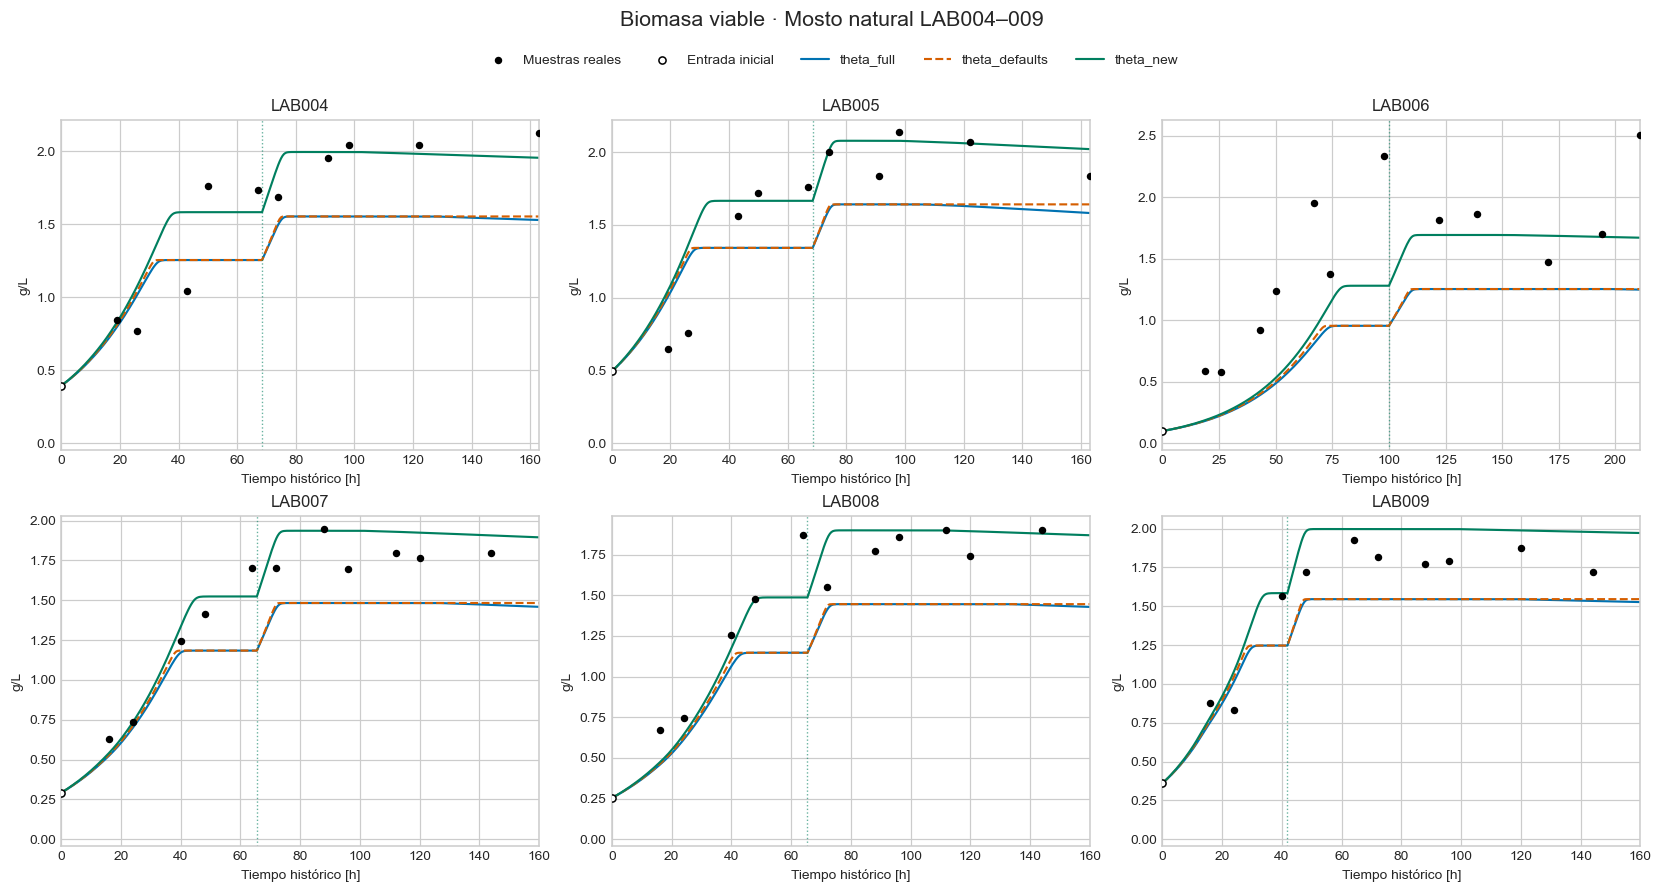

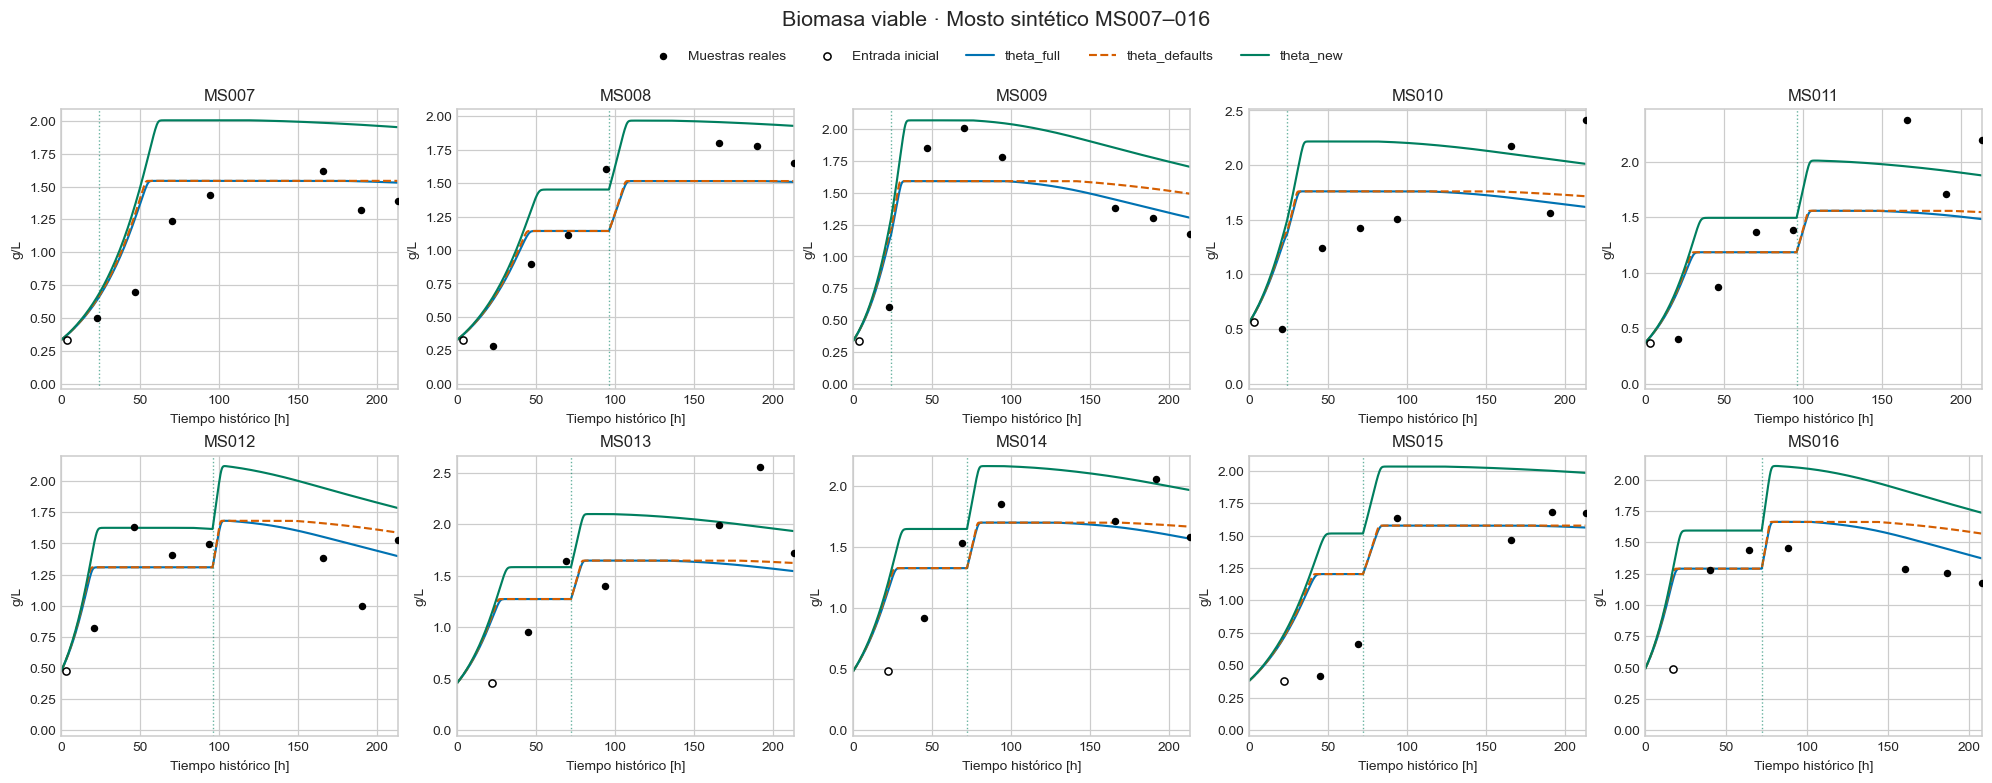

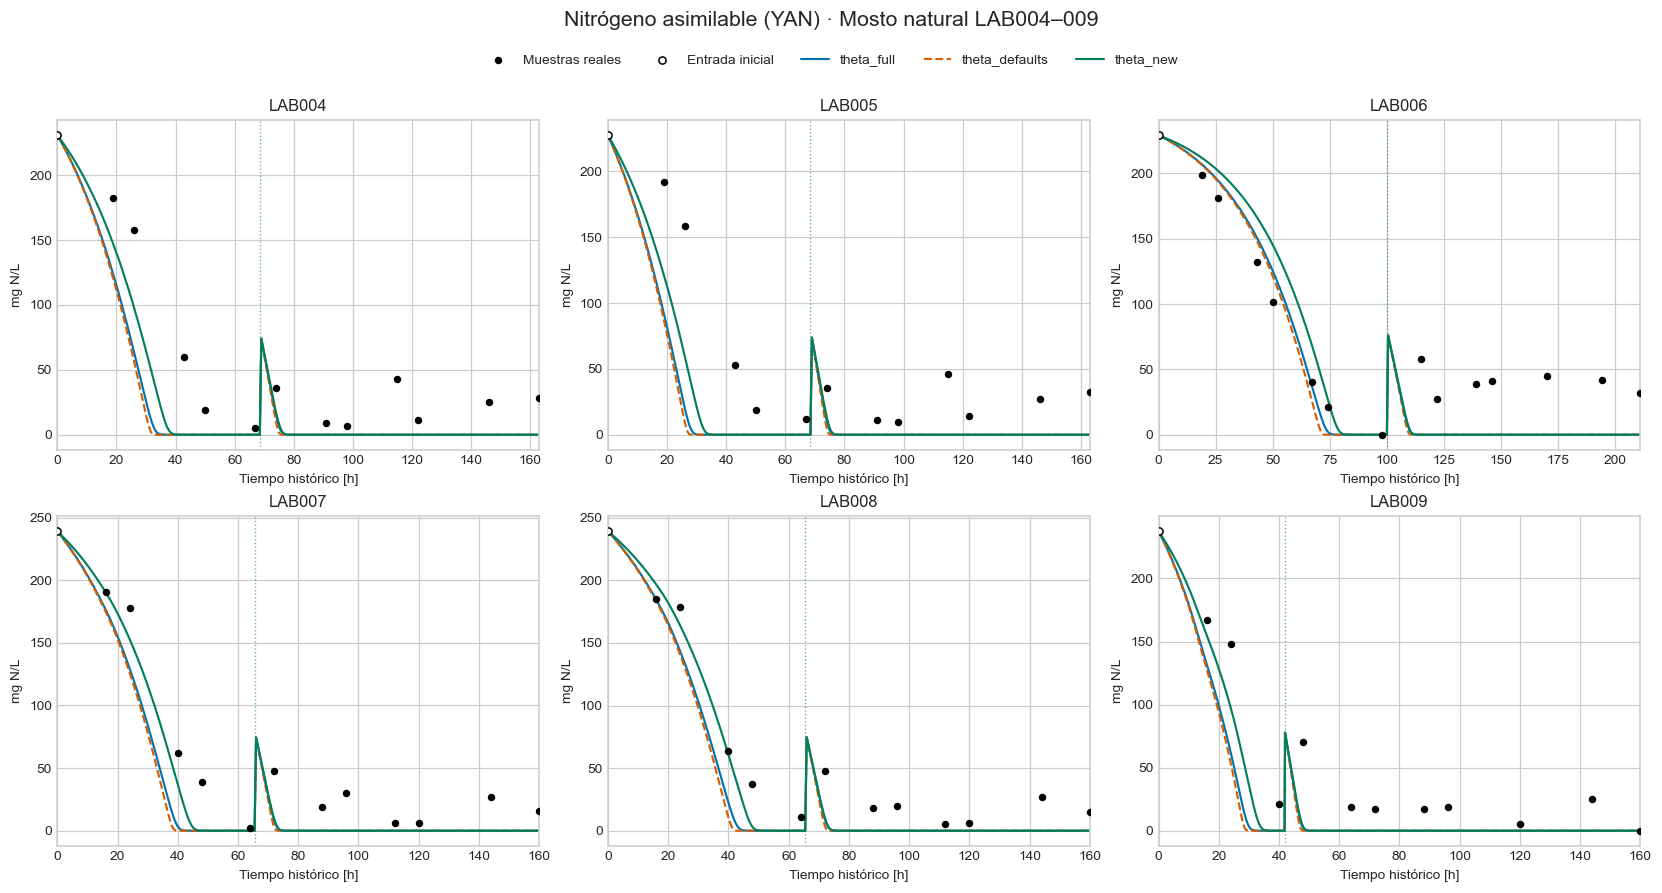

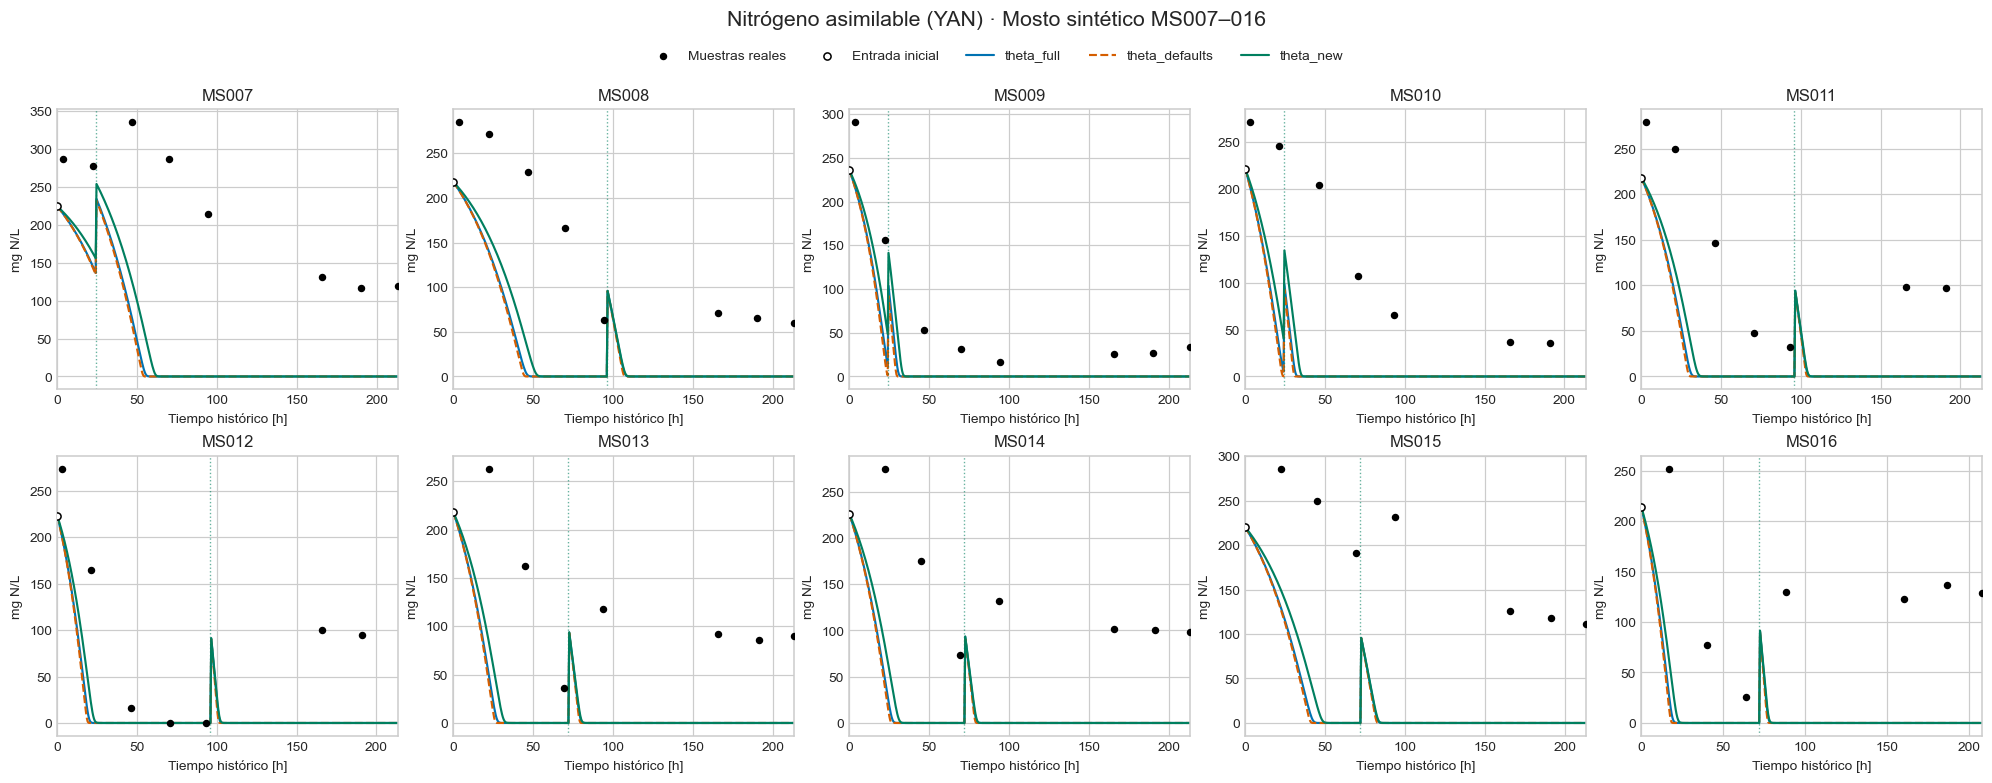

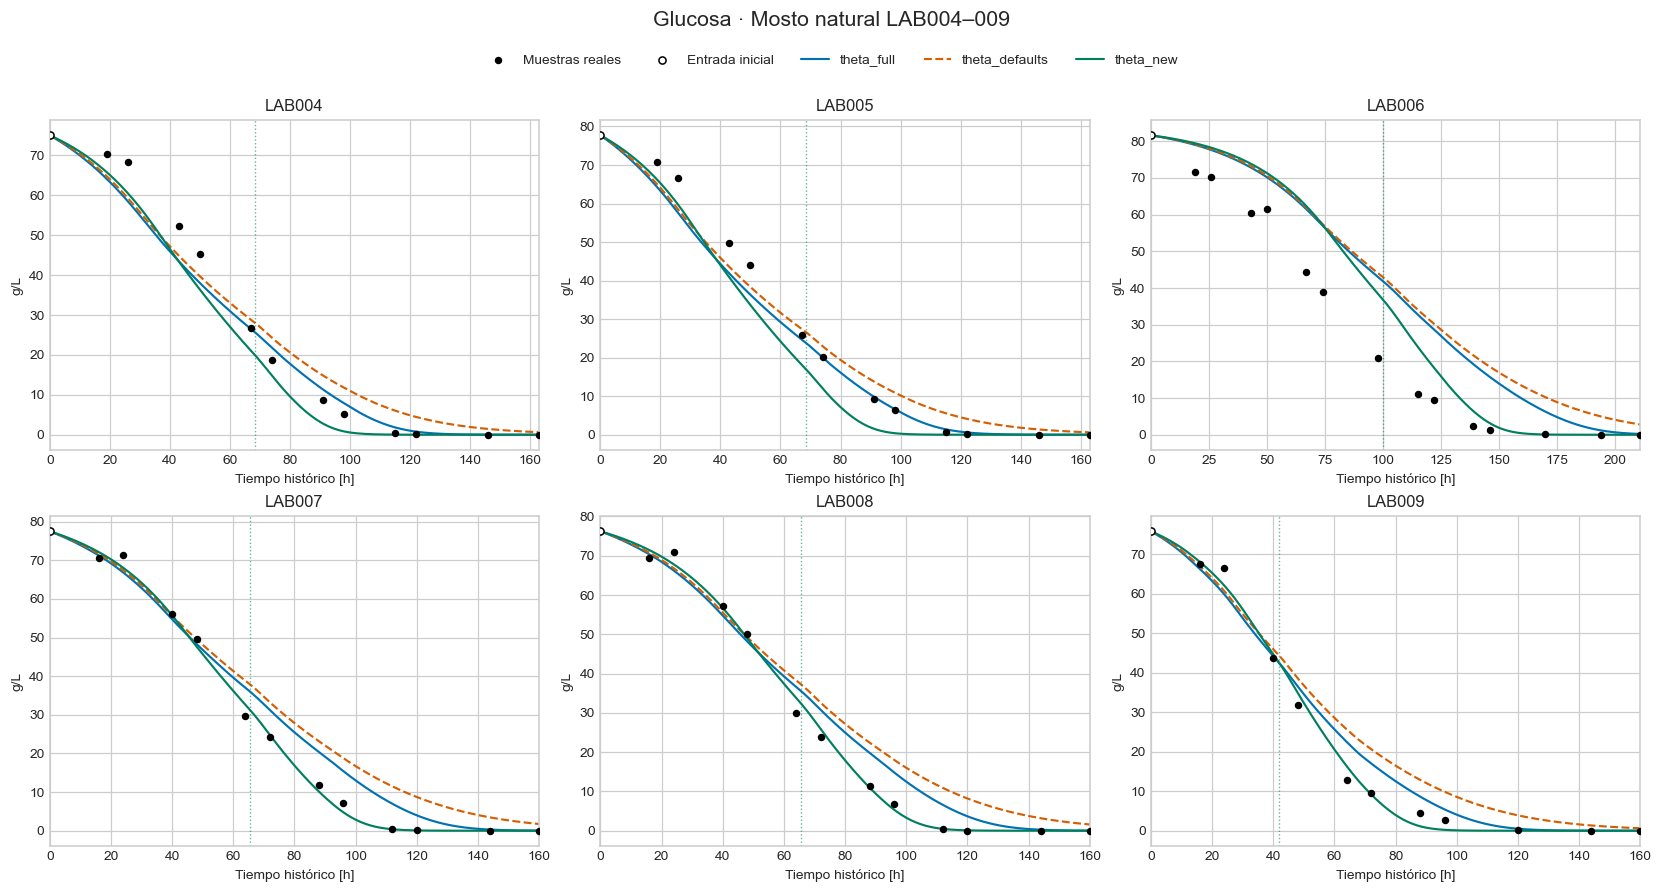

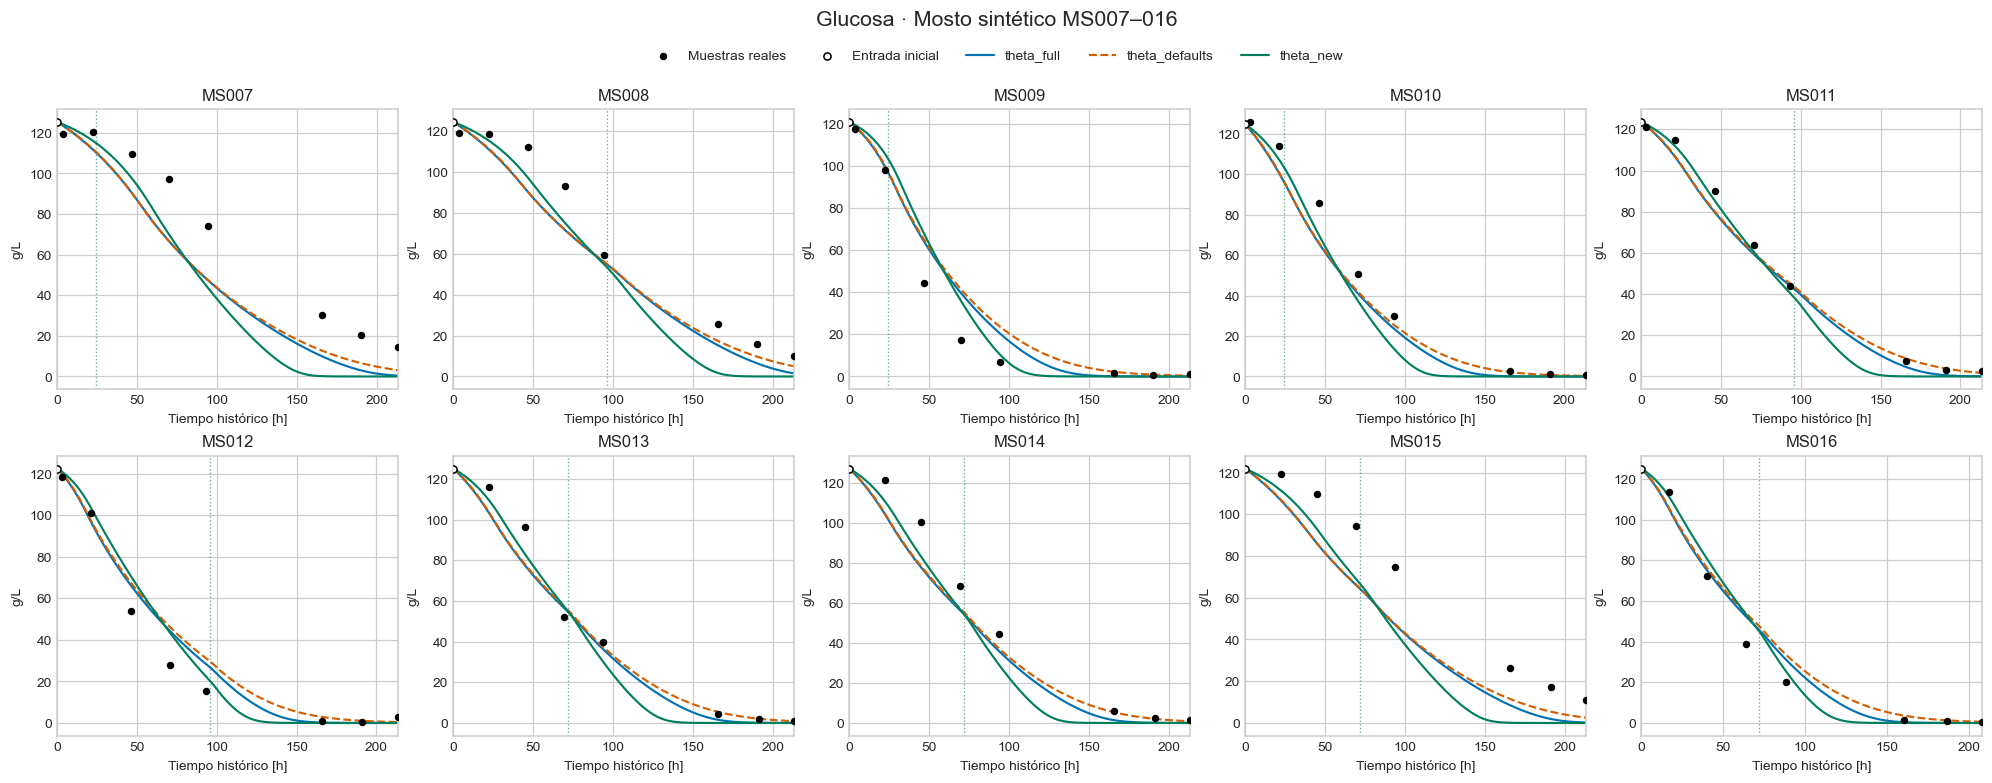

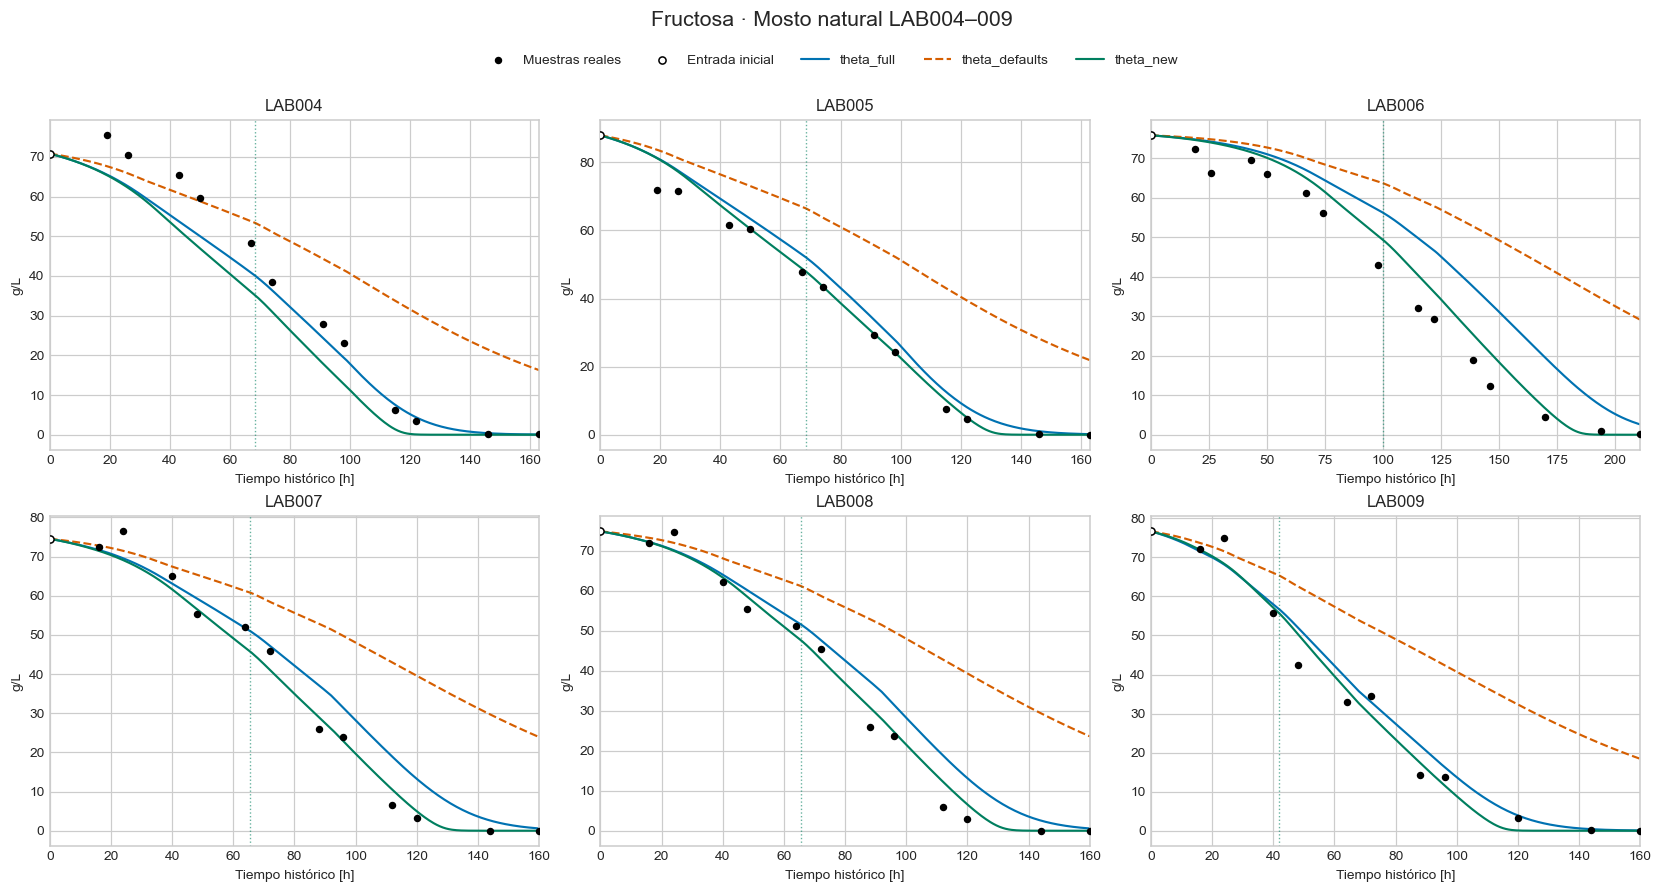

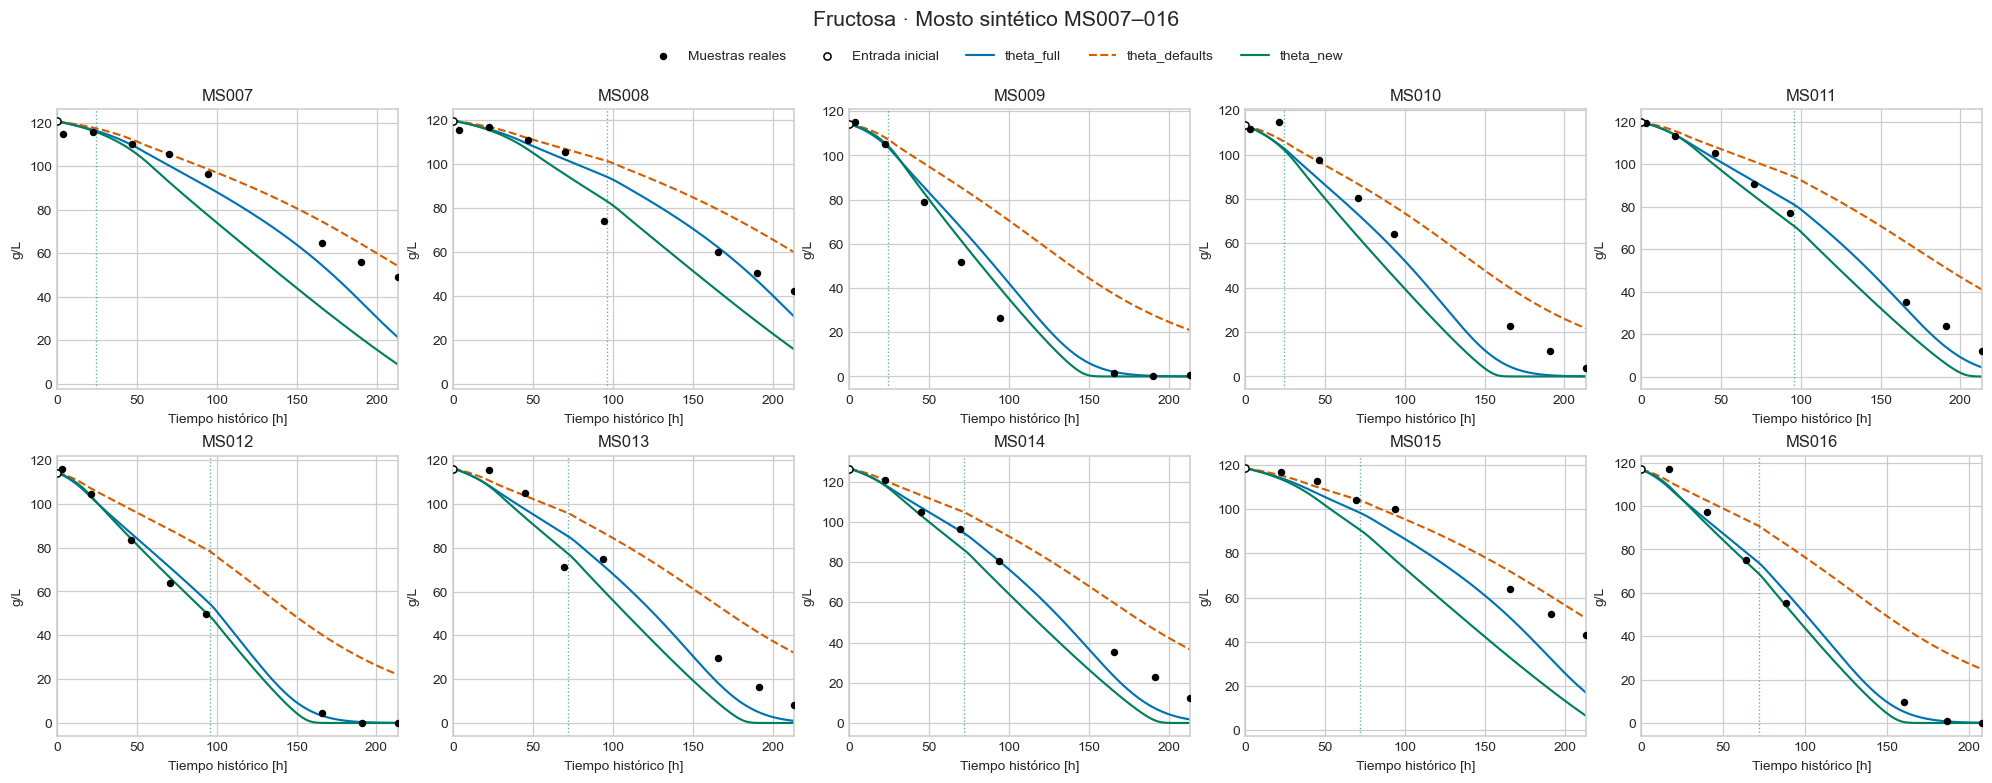

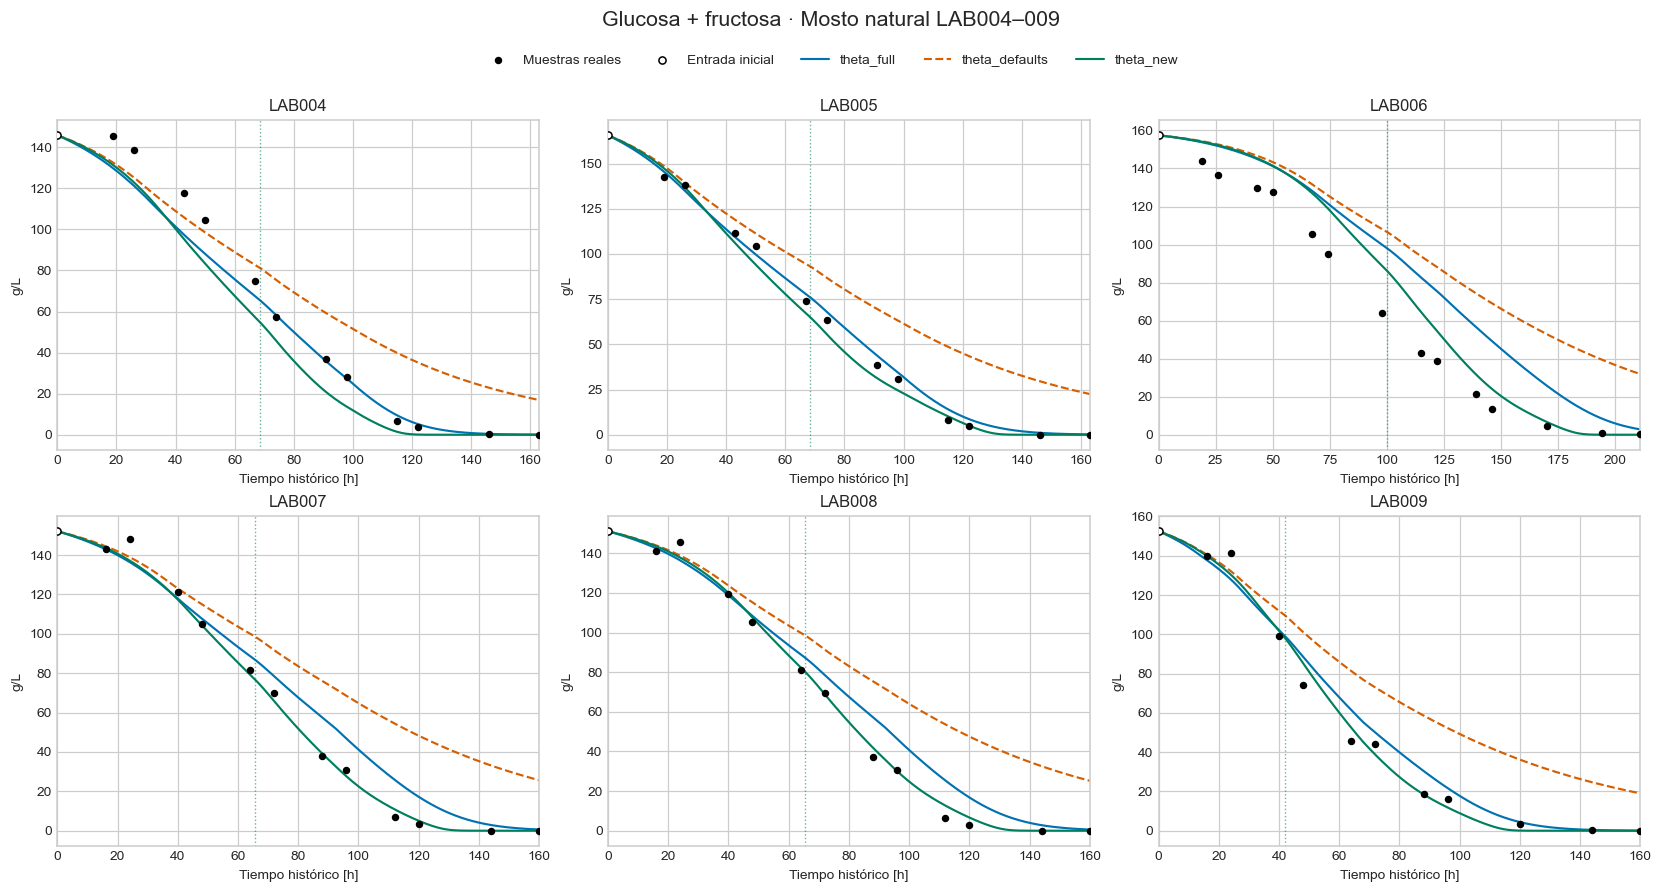

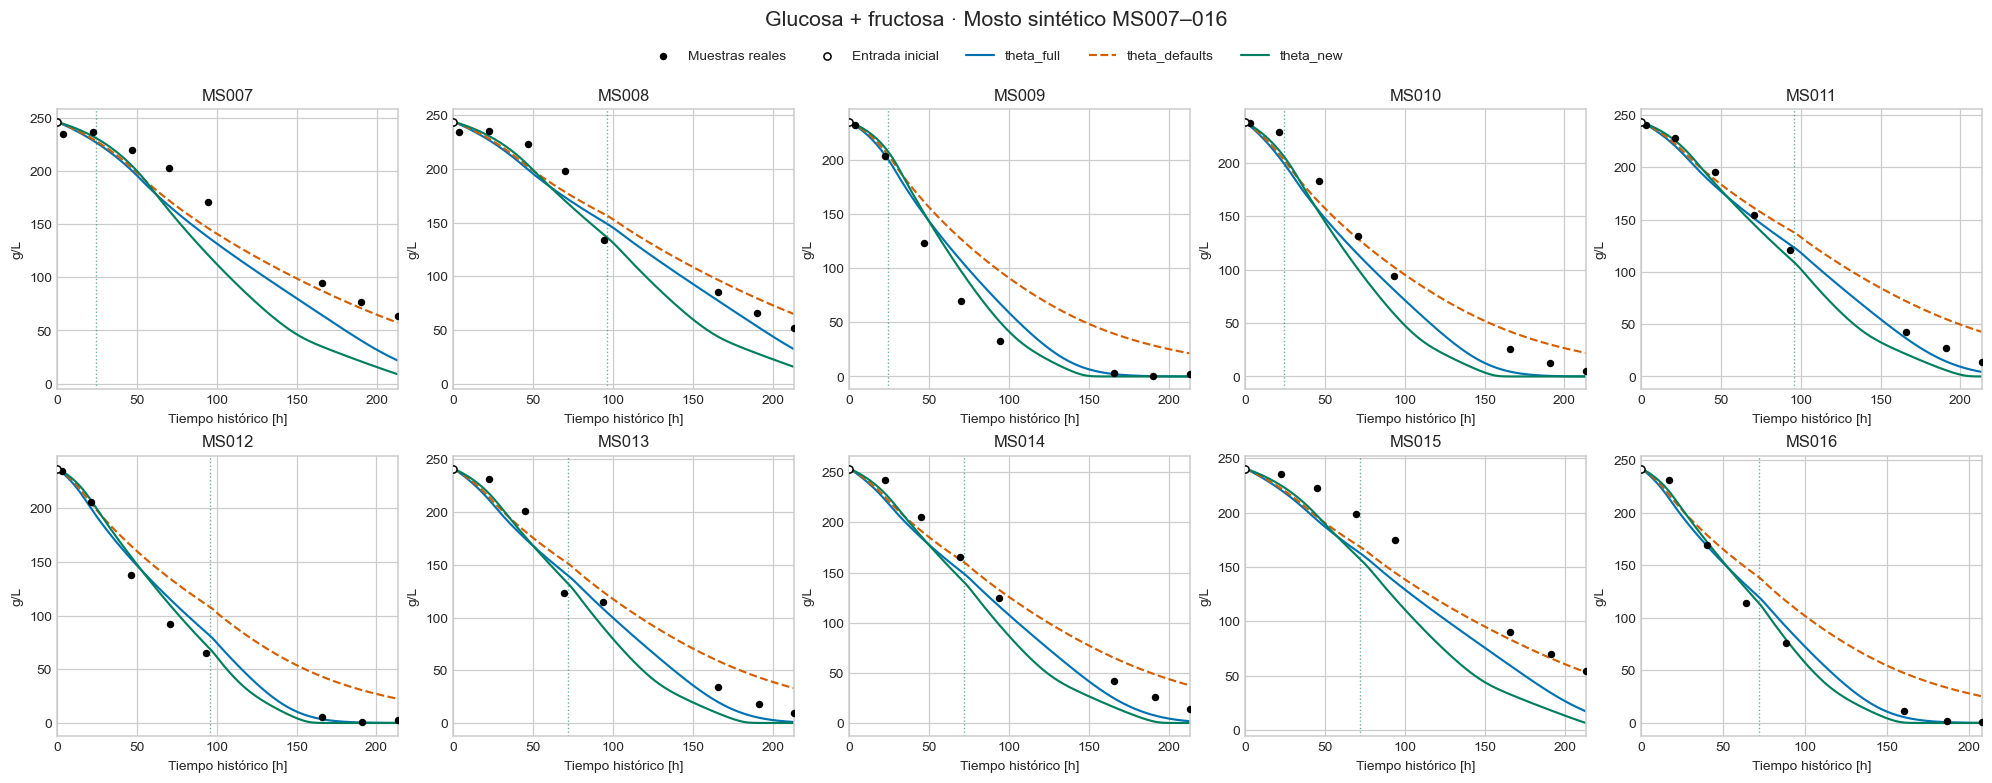

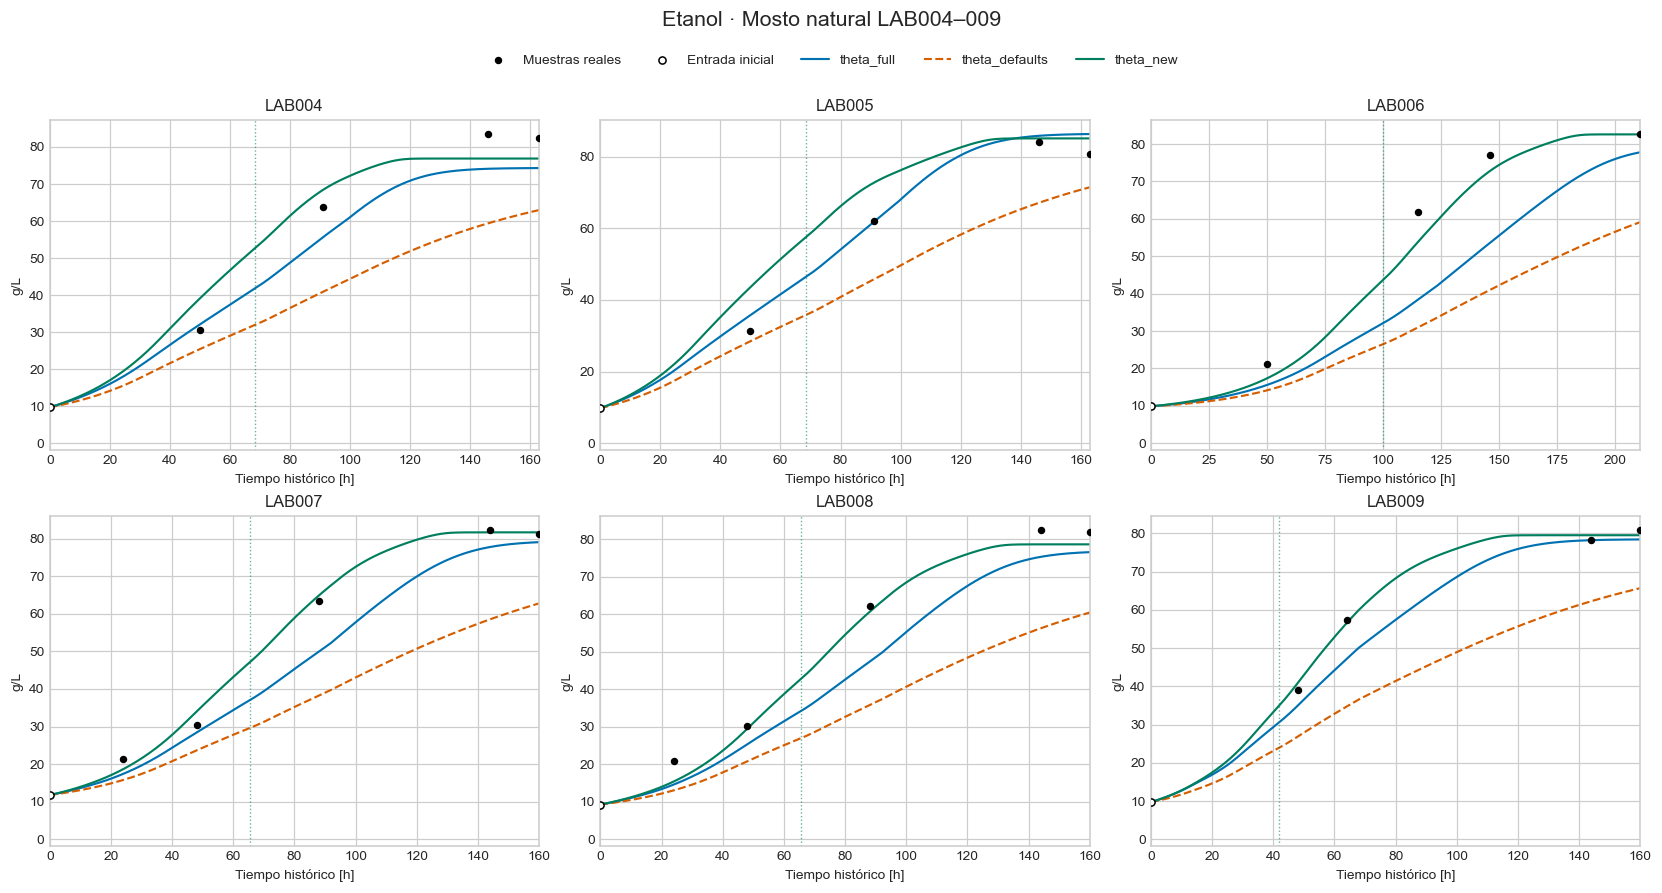

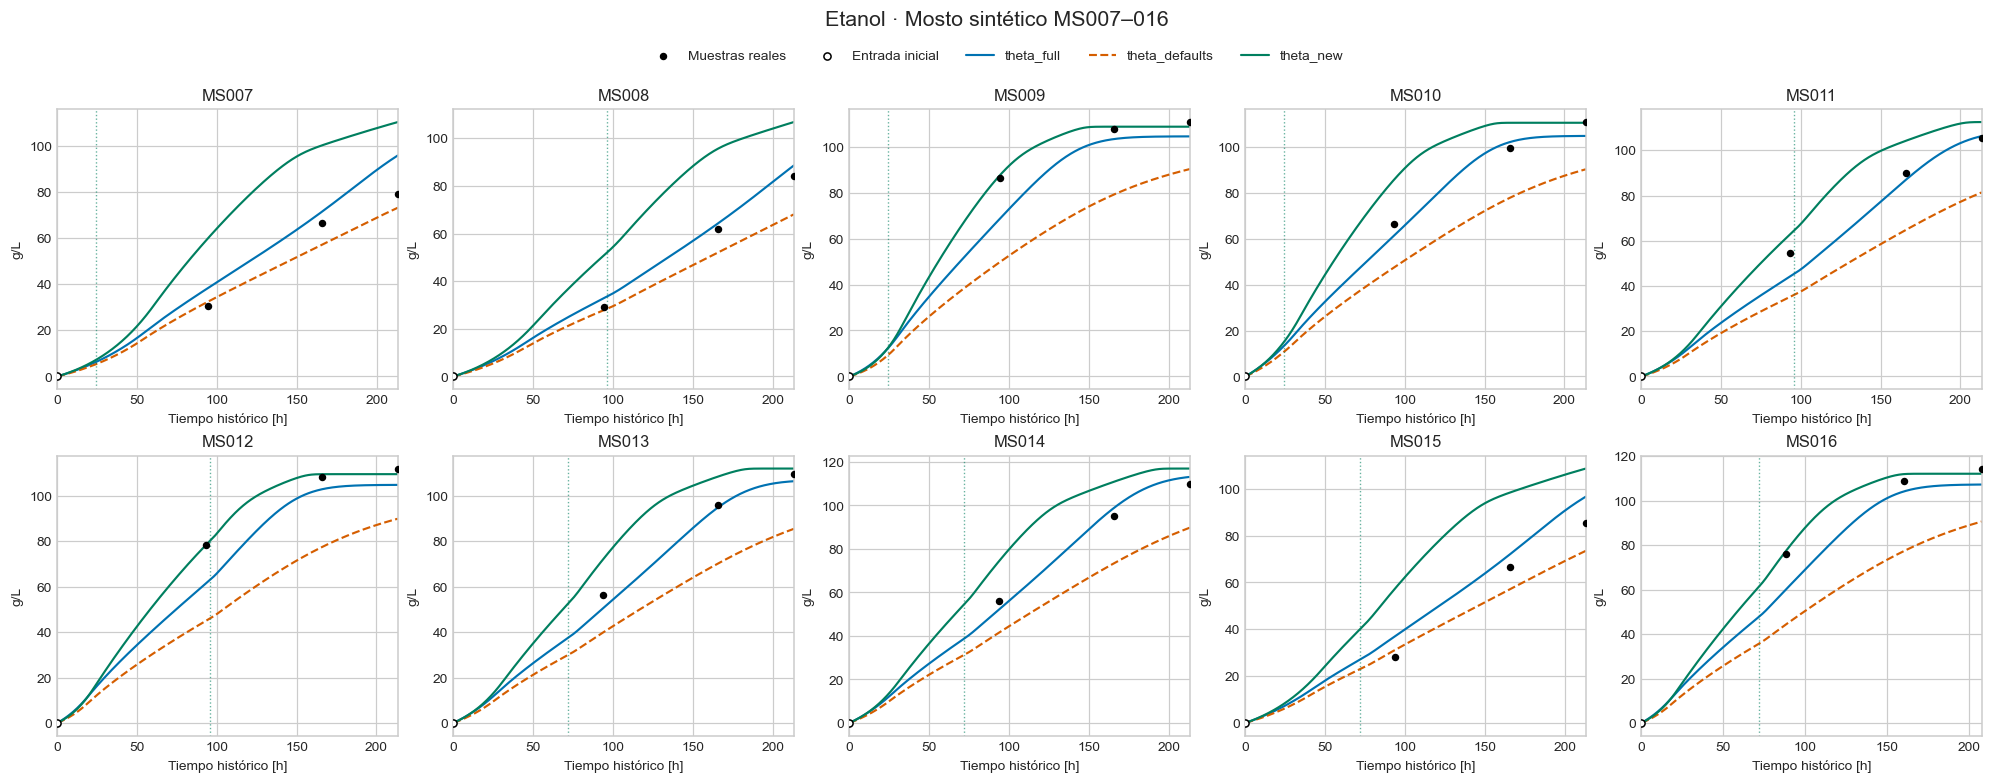

In [8]:
# Cada trayectoria densa se integra una vez y se reutiliza entre las seis figuras de variables.
plot_predictions={}
for b in batches:
    dense=np.unique(np.r_[np.arange(0,b.time[-1],.5),b.time[-1],*[t for t,a in b.pulses['N']]])
    for label in ['theta_full','theta_defaults','theta_new']:
        plot_predictions[(label,b.batch)]=model.simulate(b,VECTORS[label],dense)
        assert plot_predictions[(label,b.batch)] is not None
LABELS={'X':'Biomasa viable','N':'Nitrógeno asimilable (YAN)','G':'Glucosa','F':'Fructosa','GF':'Glucosa + fructosa','E':'Etanol'}
COLORS={'theta_new':'#007F5F','theta_full':'#0072B2','theta_defaults':'#D55E00'}
for state in ['X','N','G','F','GF','E']:
    for medium in ['natural','synthetic']:
        group=[b for b in batches if b.medium==medium]
        fig,axes=plt.subplots(2,3 if medium=='natural' else 5,figsize=(15,8) if medium=='natural' else (18,7),layout='constrained')
        factor=1000 if state=='N' else 1
        for ax,b in zip(axes.flat,group):
            times=original_times[b.batch];ix=np.searchsorted(b.time,times)
            obs=(b.observations['G']+b.observations['F'])[ix] if state=='GF' else b.observations[state][ix]
            valid=np.isfinite(obs)
            first=np.flatnonzero(valid)[0] if valid.any() else None
            mask=valid.copy()
            if first is not None:mask[first]=False
            ax.scatter(times[mask],obs[mask]*factor,color='black',s=15,zorder=5,label='Muestras reales')
            if first is not None:ax.scatter([times[first]],[obs[first]*factor],facecolors='white',edgecolors='black',s=22,zorder=6,label='Entrada inicial')
            for label in ['theta_full','theta_defaults','theta_new']:
                sim=plot_predictions[(label,b.batch)]
                value=sim['G']+sim['F'] if state=='GF' else sim[state]
                ax.plot(sim.index,value*factor,color=COLORS[label],lw=1.4,ls='--' if label=='theta_defaults' else '-',label=label)
            for t,a in b.pulses['N']:ax.axvline(t,color='#007F5F',ls=':',lw=.9,alpha=.6)
            ax.set(title=b.batch,xlabel='Tiempo histórico [h]',ylabel='mg N/L' if state=='N' else 'g/L',xlim=(0,b.time[-1]))
            lo,hi=ax.get_ylim();ax.set_ylim(min(lo,-.02*max(hi,1)),hi)
        handles,labels=axes.flat[0].get_legend_handles_labels()
        fig.suptitle(f'{LABELS[state]} · {"Mosto natural LAB004–009" if medium=="natural" else "Mosto sintético MS007–016"}',y=.995,fontsize=14)
        fig.get_layout_engine().set(rect=(0,0,1,.9));fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.96),ncol=5,frameon=False)
        plt.show();plt.close(fig)

## 8. Conclusiones, límites y conservación

Este es un reajuste natural de once parámetros; los seis restantes se heredan del theta_full histórico. No hay nueva etapa conjunta. La selección usa únicamente el objetivo de LAB004–009. Los sintéticos y LAB019–021 sirven para evaluar transferencia, sin seleccionar parámetros con ellos. Las cotas condicionan el resultado y no se afirma identificabilidad. Los pulsos naturales son las propuestas acordadas. Se conserva la conversión de 30 pg/célula y se auditan las condiciones iniciales.

In [9]:
new_n=summary.loc[('theta_new','natural'),'WRMSE']
lines=[f"- Reajuste natural seleccionado: **{natural_best['summary']['fit']}**, objetivo **{natural_best['summary']['final_wsse']:.3f}**.",
       f"- Inicialización histórica: **theta_full**; once parámetros libres y seis fijos. No se realizó etapa conjunta.",
       f"- Convergencia declarada: **{sum(r['summary']['success'] for r in natural_runs)}/{len(natural_runs)}** arranques.",
       f"- WRMSE natural sin anclas iniciales: theta_new **{new_n:.3f}**, theta_full **{summary.loc[('theta_full','natural'),'WRMSE']:.3f}**, theta_defaults **{summary.loc[('theta_defaults','natural'),'WRMSE']:.3f}**.",
       f"- Hay **{int(comparison.near_bound.ne('').sum())} parámetros** próximos a una cota.",
       '- Sintéticos evaluados sin reajuste ni selección: no participaron en el objetivo natural.',
       '- El resultado reemplaza theta_new descartado; resultados históricos conservados.']
display(Markdown('\n'.join(lines)))
assert INPUT_HASHES=={k:sha(p) for k,p in INPUTS.items()},'Cambió una entrada'
assert protected=={str(p.relative_to(ROOT)):sha(p) for root in protected_roots if root.exists() for p in root.rglob('*') if p.is_file()},'Cambió un resultado histórico'
assert set(theta_new)==set(PARAMS) and all(np.isfinite(theta_new[p]) for p in PARAMS)
assert all(model.PARAMETER_BOUNDS[p][0]<=theta_new[p]<=model.PARAMETER_BOUNDS[p][1] for p in PARAMS)
assert all(theta_new[p]==reference[p] for p in FIXED6)
manifest={'created_at':datetime.now(ZoneInfo('America/Santiago')).isoformat(),'config':CONFIG,
    'signature':signature,'inputs':{k:{'path':str(p.relative_to(ROOT)),'sha256':INPUT_HASHES[k]} for k,p in INPUTS.items()},
    'experiments':list(LABS),'evaluation_only_synthetic':list(MS),'excluded_labs':['LAB010','LAB011','LAB012'],'fixed_six':list(FIXED6),
    'free_eleven':list(FREE11),'regularized_parameters':[],'reference':reference,
    'selected_natural_fit':natural_best['summary'],
    'source_notebook_sha256':sha(OUT/'theta_new.source.ipynb'),'historical_files_preserved':len(protected),'calibration_not_holdout':True,
    'temperature_audit':thermal_audit,'pulse_table':pulse_table.to_dict('records'),
    'parameter_comparison':comparison.reset_index().to_dict('records'),
    'metrics':metrics.to_dict('records'),'variable_metrics':variable_metrics.reset_index().to_dict('records'),'numerical_check':numeric.to_dict('records'),'conclusions':lines}
for filename,value in [('theta_new.json',theta_new),('manifest.json',manifest)]:
    (OUT/filename).write_text(json.dumps(value,indent=2,ensure_ascii=False),encoding='utf-8')
assert numeric.max_delta_sigma.max()<.01, 'La integración requiere revisión'
print('Verificado: 6 experimentos naturales ajustados; sintéticos solo evaluados; theta_new reemplazado; archivos anteriores intactos; sin commit ni push.')

- Reajuste natural seleccionado: **natural_01**, objetivo **2357.142**.
- Inicialización histórica: **theta_full**; once parámetros libres y seis fijos. No se realizó etapa conjunta.
- Convergencia declarada: **4/4** arranques.
- WRMSE natural sin anclas iniciales: theta_new **2.299**, theta_full **2.922**, theta_defaults **4.955**.
- Hay **2 parámetros** próximos a una cota.
- Sintéticos evaluados sin reajuste ni selección: no participaron en el objetivo natural.
- El resultado reemplaza theta_new descartado; resultados históricos conservados.

Verificado: 6 experimentos naturales ajustados; sintéticos solo evaluados; theta_new reemplazado; archivos anteriores intactos; sin commit ni push.


## 9. Holdout químico externo: LAB019–021

LAB019–021 no participaron en el reajuste natural ni en la referencia del ajuste de theta_new. Se congelan theta_new, theta_full y theta_defaults. No se utiliza la capa de CO₂ ni se reajustan parámetros con esta cohorte, ya explorada en otros análisis; es una evaluación externa de parámetros, no una validación ciega.

Se reutiliza la tabla química auditada existente, conservando faltantes, flags y correcciones documentadas de dilución de etanol. YAN procede del CSV corregido previamente acordado (resta de 30 mg N/L y truncado a cero), sin segundo descuento ni offset añadido a la predicción. Se muestra YAN original como referencia. NUT tiene extracción provisional: se conserva con su intervalo, sin puntuar su error temporal.

**Corrección de las condiciones iniciales del holdout:** se reutilizan los siete estados iniciales acordados y archivados en `co2_lab016_021_recalibration_v3_artifacts/initial_conditions_corrected_clock.csv`, también mostrados en el EXECUTED de v3. X0 es 0.2831619028436019, 0.1533416694312796 y 0.1361529277251185 g/L para LAB019, LAB020 y LAB021; Xd0 es 0.032661 g/L en los tres. La primera ejecución de este holdout usó erróneamente la biomasa cruda de m1 en lugar de esta corrección. Sus figuras, errores y conclusiones quedan sustituidos por la presente ejecución.

Las muestras observadas Oculyze conservan sus valores medidos (X = concentración total × viabilidad × 0.03; Xd = total menos viable). No se reemplaza la observación m1 por X0 corregida: se muestran ambas por separado y m1 se excluye de los errores. La tabla de auditoría distingue la observación m1 de la condición inicial utilizada y documenta la fuente archivada. Se conserva t0 de inoculación del Excel. La primera nutrición está incluida en la condición inicial y no se repite; la segunda aporta 80 mg N/L a la hora documentada en el Excel.

Hay 12 muestras químicas numeradas por LAB y 11 muestras Oculyze: m12 no tiene biomasa. Se conservan sus otras mediciones y los faltantes de X/Xd permanecen ausentes.

In [10]:
H_LABS=('LAB019','LAB020','LAB021')
assert not set(H_LABS).intersection(LABS+MS)
H_DIR=FM/'data/mem2026/LAB019-021'
H_PATHS={'initial_conditions_v3':FM/'laboratory_2026/notebooks/diagnostics/co2_lab016_021_recalibration_v3_artifacts/initial_conditions_corrected_clock.csv',
 'chemistry_qc':FM/'laboratory_2026/results/lab019_021_theta_full_holdout/chemistry_observations_qc.csv',
 'metadata':H_DIR/'Mediciones-Offline-LAB019-021.xlsx','corrected_YAN':H_DIR/'YAN_muestras_corregidas.csv',
 'NUT_intervals':FM/'laboratory_2026/results/lab019_021_replica_vs_originals_data_comparison/replica_measurements_with_NUT.csv',
 'temperature_pointer':H_DIR/'backup_global_temperatura_completo.csv',
 **{f'oculyze_{lab}':H_DIR/f'Oculyze_report_{lab}.csv' for lab in H_LABS}}
def h_sha(path):
    digest=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):digest.update(block)
    return digest.hexdigest()
def h_resolve_lfs(path):
    with path.open('rb') as f:head=f.read(512)
    if not head.startswith(b'version https://git-lfs.github.com/spec/v1'):return path,None
    text=head.decode();oid=re.search(r'oid sha256:([0-9a-f]{64})',text).group(1)
    obj=ROOT/'.git/lfs/objects'/oid[:2]/oid[2:4]/oid
    assert obj.is_file(),'Falta objeto LFS completo; no sustituir por backup parcial'
    assert obj.stat().st_size==int(re.search(r'size ([0-9]+)',text).group(1)) and h_sha(obj)==oid
    return obj,oid
H_TEMP_PATH,H_TEMP_OID=h_resolve_lfs(H_PATHS['temperature_pointer'])
H_PATHS['temperature_full_object']=H_TEMP_PATH
H_HASHES={k:h_sha(path) for k,path in H_PATHS.items()}
H_FROZEN_PATHS={name:OUT/name for name in ['theta_new.json','fit_checkpoint.json']}
H_FROZEN_HASHES={k:h_sha(path) for k,path in H_FROZEN_PATHS.items()}
H_VECTORS={name:dict(VECTORS[name]) for name in ['theta_new','theta_full','theta_defaults']}
H_THETA_SNAPSHOT={name:dict(theta) for name,theta in H_VECTORS.items()}
h_qc=pd.read_csv(H_PATHS['chemistry_qc']);assert h_qc.groupby('lab').size().eq(12).all()
h_qc['sample']=h_qc['sample'].astype(str);h_qc['YAN_original_mg_l']=h_qc.YAN_mg_l
h_yan=pd.read_csv(H_PATHS['corrected_YAN'],dtype={'sample':str})
assert len(h_yan)==39 and not h_yan.duplicated(['lab','sample']).any()
h_qc=h_qc.drop(columns=['YAN_mg_l','N_kg_m3']).merge(h_yan[['lab','sample','YAN_mg_l']],on=['lab','sample'],validate='one_to_one')
assert np.allclose(h_qc.YAN_mg_l,np.maximum(h_qc.YAN_original_mg_l-30.,0.))
h_qc['N_kg_m3']=h_qc.YAN_mg_l/1000
h_experiments=pd.read_excel(H_PATHS['metadata'],sheet_name='Experimentos').set_index('CodigoLab')
h_nutrition=pd.read_excel(H_PATHS['metadata'],sheet_name='Nutricion')
h_pulses={};h_t0={};h_biomass=[];h_cero=[]
for lab in H_LABS:
    t0=pd.Timestamp(h_experiments.loc[lab,'FechaHora_Inoculacion']);h_t0[lab]=t0
    nut=h_nutrition[(h_nutrition.CodigoLab==lab)&h_nutrition.Pulso.eq('Pulso 2')]
    assert len(nut)==1 and np.isclose(nut.YAN_dosis_mg_L.iloc[0],80.)
    h_pulses[lab]=((float((pd.Timestamp(nut.FechaHora_Pulso.iloc[0])-t0).total_seconds()/3600),.08),)
    report=pd.read_csv(H_PATHS[f'oculyze_{lab}']);cero=report[report.Name.str.upper().eq('CERO')];assert len(cero)==1
    h_cero.append({'lab':lab,'Concentration_CERO':float(cero.Concentration.iloc[0]),'Viability_CERO_pct':float(cero.Viability.iloc[0])})
    for row in report.itertuples(index=False):
        name=str(row.Name);prefix=lab+'-'
        if not name.startswith(prefix) or not name[len(prefix):].isdigit():continue
        sample=str(int(name[len(prefix):]));chemical=h_qc[(h_qc.lab==lab)&h_qc['sample'].eq(sample)]
        assert len(chemical)==1,(lab,sample)
        fraction=float(row.Viability)/100;assert 0<=fraction<=1
        total=float(row.Concentration)*.03
        h_biomass.append({'lab':lab,'sample':sample,'X':total*fraction,'Xd':total*(1-fraction),
            'X_total':total,'biomass_source_time':str(row.Description)})
h_biomass=pd.DataFrame(h_biomass);assert h_biomass.groupby('lab').size().eq(11).all()
h_qc=h_qc.merge(h_biomass,on=['lab','sample'],how='left',validate='one_to_one')
assert len(h_qc)==36 and h_qc[h_qc['sample'].eq('12')][['X','Xd']].isna().all().all()
nut_intervals=pd.read_csv(H_PATHS['NUT_intervals'],dtype={'sample':str})
h_nut_points=h_yan[h_yan.is_NUT].merge(nut_intervals[nut_intervals['sample'].eq('NUT')]
    [['lab','sample','time_lower_h','time_upper_h']],on=['lab','sample'],validate='one_to_one')
assert len(h_nut_points)==3 and h_nut_points.time_provisional.all()
h_archived_initials=pd.read_csv(H_PATHS['initial_conditions_v3']).set_index('lab')
assert set(H_LABS).issubset(h_archived_initials.index)
h_initials={};h_initial_audit=[]
for lab in H_LABS:
    row=h_qc[(h_qc.lab==lab)&h_qc['sample'].eq('1')].iloc[0]
    archived=h_archived_initials.loc[lab]
    ini={state:float(archived[state]) for state in model.STATE_NAMES}
    for state,column in {'N':'N_kg_m3','G':'G_g_l','F':'F_g_l','E':'E_g_l','Gly':'Gly_g_l'}.items():
        assert np.isclose(ini[state],float(row[column])),(lab,state)
    assert all(ini[state]==float(archived[state]) for state in model.STATE_NAMES)
    assert all(np.isfinite(v) and v>=0 for v in ini.values());h_initials[lab]=ini
    h_initial_audit.append({'lab':lab,'t0':str(h_t0[lab]),'m1_chemical_time':row.sample_timestamp,
        'm1_oculyze_description':row.biomass_source_time,'m1_measured_X_g_L':float(row.X),
        'm1_measured_Xd_g_L':float(row.Xd),'initial_condition_source':str(H_PATHS['initial_conditions_v3'].relative_to(ROOT)),
        'archived_source_description':str(archived['source']),'pulse_h':h_pulses[lab][0][0],'dose_mg_N_L':80.,**ini})
display(pd.DataFrame(h_initial_audit));display(pd.DataFrame(h_cero))
print('YAN: CSV corregido existente, sin doble descuento; NUT provisional no puntuado.')

,lab,t0,m1_chemical_time,m1_oculyze_description,m1_measured_X_g_L,m1_measured_Xd_g_L,initial_condition_source,archived_source_description,pulse_h,dose_mg_N_L,X,Xd,N,G,F,E,Gly
0,LAB019,2026-09-21 17:00:00,2026-09-21 15:50:00,21/09/2026 17:20,0.829503,0.029997,fermentation_model\laboratory_2026\notebooks\d...,N inicial m1 del CSV corregido; biomasa viable...,64.333333,80.0,0.283162,0.032661,0.230025,79.19,78.97,12.075372,1.22
1,LAB020,2026-09-21 17:00:00,2026-09-21 15:50:00,21/09/2026 17:20,0.406693,0.004607,fermentation_model\laboratory_2026\notebooks\d...,N inicial m1 del CSV corregido; biomasa viable...,71.666667,80.0,0.153342,0.032661,0.225556,77.94,79.52,11.917524,1.38
2,LAB021,2026-09-21 17:00:00,2026-09-21 15:50:00,21/09/2026 17:20,0.381465,0.018435,fermentation_model\laboratory_2026\notebooks\d...,N inicial m1 del CSV corregido; biomasa viable...,47.500000,80.0,0.136153,0.032661,0.231202,80.19,81.04,11.759676,1.28


,lab,Concentration_CERO,Viability_CERO_pct
0,LAB019,2.96,75.32
1,LAB020,2.27,64.41
2,LAB021,2.00,51.92


YAN: CSV corregido existente, sin doble descuento; NUT provisional no puntuado.


### 9.1 Temperatura y entradas del holdout

Se usa el backup completo de temperatura, resolviendo el objeto Git LFS local y verificando su SHA-256/tamaño si el archivo es un puntero. No se modifica el checkout ni se sustituye por el backup parcial. Se aplica el mismo filtro de calibración: medianas de 30 min, mediana móvil centrada de 90 min y Butterworth de orden 2/período de corte 4 h, por tramos sin mezclar cambios de consigna ni huecos. La malla del modelo conserva 2 h más muestras y cambios térmicos; los extremos utilizan la lectura filtrada más cercana. Los huecos interiores se auditan. LAB019–021 transcurre después del cambio de hora de septiembre y no tiene saltos de horario dentro de la cohorte.

C:\Users\claud\AppData\Local\Temp\ipykernel_12704\1199479312.py:2: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(H_TEMP_PATH,usecols=['timestamp','fermentador','T','SP'],chunksize=250000):


,lab,raw_rows,sensor_start_h,sensor_end_h,horizon_h,initial_extension_h,final_extension_h,interior_gaps_h
0,LAB019,189374,0.25,182.75,166.0,0.25,0.0,[]
1,LAB020,189373,0.25,182.75,166.0,0.25,0.0,[]
2,LAB021,189373,0.25,182.75,166.0,0.25,0.0,[]


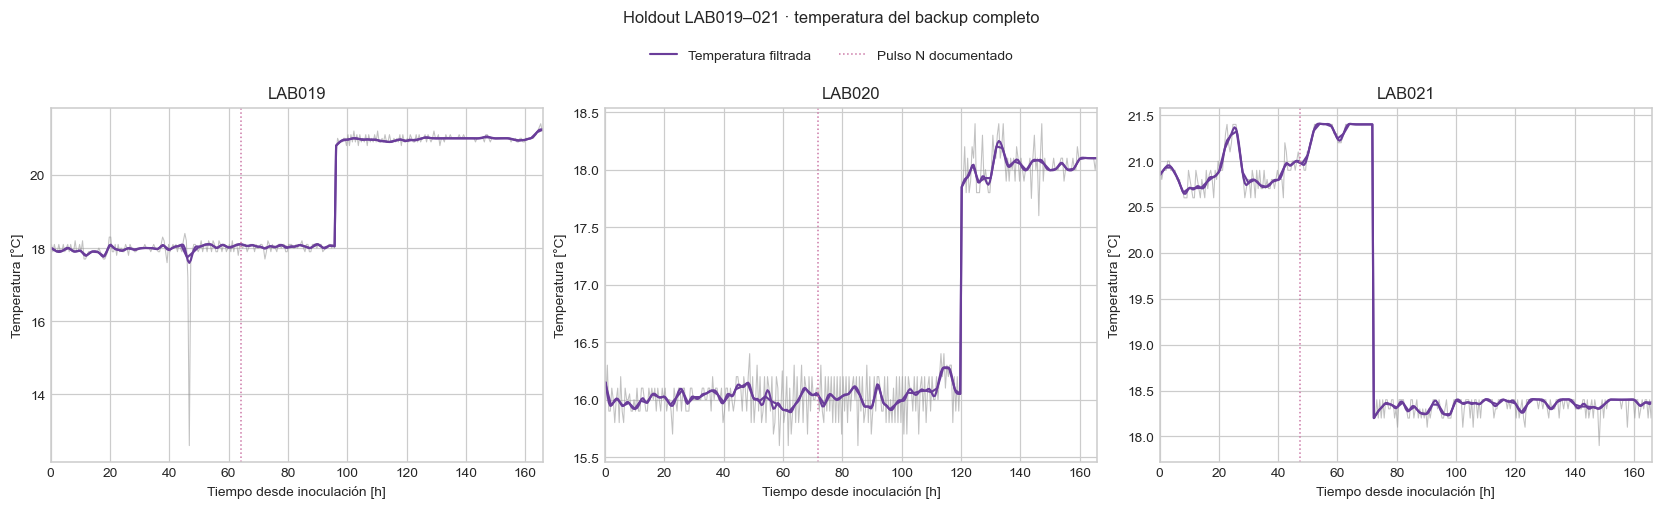

In [11]:
h_parts=[];h_start=min(h_t0.values());h_horizon=float(h_qc.t_h.max());h_end=h_start+pd.Timedelta(hours=h_horizon+24)
for chunk in pd.read_csv(H_TEMP_PATH,usecols=['timestamp','fermentador','T','SP'],chunksize=250000):
    mask=chunk.timestamp.ge(str(h_start))&chunk.timestamp.le(str(h_end))
    if mask.any():h_parts.append(chunk.loc[mask].copy())
assert h_parts,'Sin temperatura del holdout en el archivo completo'
h_raw=pd.concat(h_parts,ignore_index=True);h_raw.timestamp=pd.to_datetime(h_raw.timestamp,errors='coerce')
for col in ['T','SP']:h_raw[col]=pd.to_numeric(h_raw[col],errors='coerce')
h_profiles={};h_batches=[];h_temperature_audit=[]
for lab in H_LABS:
    reactor=h_experiments.loc[lab,'Fermentador']
    raw=h_raw[h_raw.fermentador.eq(reactor)].dropna(subset=['timestamp','T']).sort_values('timestamp',kind='stable')
    dup=raw[raw.timestamp.duplicated(keep=False)]
    if len(dup):assert dup.groupby('timestamp')[['T','SP']].nunique().le(1).all().all()
    raw=raw.drop_duplicates('timestamp');raw['t_h']=(raw.timestamp-h_t0[lab]).dt.total_seconds()/3600
    raw=raw[raw.t_h.ge(0)];assert len(raw)>100
    profile=raw.set_index('timestamp')[['T','SP']].resample('30min').median().dropna(subset=['T']).reset_index()
    profile['t_h']=(profile.timestamp-h_t0[lab]).dt.total_seconds()/3600+.25
    profile=profile[profile.t_h.between(0,raw.t_h.max())].copy()
    gap=profile.t_h.diff().gt(.500001);step=profile.SP.diff().abs().gt(.5)
    profile['segment']=(gap|step).cumsum();profile['filtered']=np.nan
    for seg,g in profile.groupby('segment'):
        smooth=g['T'].rolling(3,center=True,min_periods=1).median().to_numpy()
        profile.loc[g.index,'filtered']=sosfiltfilt(butter(2,.25,fs=2.,output='sos'),smooth) if len(smooth)>9 else smooth
    h_profiles[lab]=profile;horizon=float(h_qc.loc[h_qc.lab.eq(lab),'t_h'].max())
    switches=profile.loc[profile.segment.diff().fillna(0).ne(0),'t_h'].to_numpy()
    times=h_qc.loc[h_qc.lab.eq(lab),'t_h'].to_numpy()
    knots=np.r_[np.arange(0,horizon+1e-9,2.),switches,switches-.5]
    grid=np.unique(np.r_[times,knots[(knots>=0)&(knots<=horizon)]])
    observations={s:np.full(len(grid),np.nan) for s in model.STATE_NAMES}
    mapping={'X':'X','Xd':'Xd','N':'N_kg_m3','G':'G_g_l','F':'F_g_l','E':'E_g_l','Gly':'Gly_g_l'}
    rows=h_qc[h_qc.lab.eq(lab)].sort_values('t_h');idx=np.searchsorted(grid,rows.t_h)
    for state,column in mapping.items():observations[state][idx]=rows[column].to_numpy(dtype=float)
    h_batches.append(model.BatchData(medium='natural',batch=lab,time=grid,
        temperature_c=np.interp(grid,profile.t_h,profile.filtered),
        pulses={**{s:() for s in model.INPUT_CHANNELS},'N':h_pulses[lab]},
        observations=observations,initials=dict(h_initials[lab])))
    gaps=[[float(profile.iloc[i-1].t_h),float(profile.iloc[i].t_h)] for i in np.flatnonzero(gap.to_numpy())]
    h_temperature_audit.append({'lab':lab,'raw_rows':len(raw),'sensor_start_h':profile.t_h.min(),
        'sensor_end_h':profile.t_h.max(),'horizon_h':horizon,'initial_extension_h':profile.t_h.min(),
        'final_extension_h':max(0.,horizon-profile.t_h.max()),'interior_gaps_h':gaps})
display(pd.DataFrame(h_temperature_audit))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
for ax,b in zip(axes,h_batches):
    profile=h_profiles[b.batch]
    for seg,g in profile.groupby(profile.t_h.diff().gt(.500001).cumsum()):
        ax.plot(g.t_h,g['T'],color='#999999',lw=.7,alpha=.6)
        ax.plot(g.t_h,g.filtered,color='#6A3D9A',lw=1.4)
    ax.plot(b.time,b.temperature_c,color='#6A3D9A',lw=1.4,label='Temperatura filtrada')
    for t,a in b.pulses['N']:ax.axvline(t,color='#CC79A7',ls=':',lw=1,label='Pulso N documentado')
    ax.set(title=b.batch,xlabel='Tiempo desde inoculación [h]',ylabel='Temperatura [°C]',xlim=(0,b.time[-1]))
fig.suptitle('Holdout LAB019–021 · temperatura del backup completo',y=.995)
fig.get_layout_engine().set(rect=(0,0,1,.85));handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.94),ncol=2,frameon=False)
plt.show();plt.close(fig)

### 9.2 Errores y predicciones congeladas

Se evalúan los siete estados y G+F por separado con las mediciones disponibles. G+F no se duplica en el WRMSE global. Se muestra también el WRMSE de las variables prioritarias X/N/G/F/E. Las entradas m1 y NUT provisional no se puntúan. Los flags blandos se conservan en el error principal; una tabla secundaria muestra el efecto de excluirlos. No se infiere azúcar desde densidad ni se reajustan parámetros. La comprobación numérica contrasta pasos máximos de integración de 2 h y 0.5 h.

In [12]:
h_metrics=[];h_predictions={};h_numeric=[]
h_state_columns={'X':'X','Xd':'Xd','N':'YAN_mg_l','G':'G_g_l','F':'F_g_l','GF':'GF_g_l','E':'E_g_l','Gly':'Gly_g_l'}
for label,theta in H_VECTORS.items():
    for b in h_batches:
        rows=h_qc[h_qc.lab.eq(b.batch)].sort_values('t_h');times=rows.t_h.to_numpy()
        dense=np.unique(np.r_[np.arange(0,b.time[-1],.25),times,b.time[-1],*[t for t,a in b.pulses['N']]])
        pred=model.simulate(b,theta,dense);assert pred is not None and np.isfinite(pred.to_numpy()).all()
        pred['GF']=pred.G+pred.F;h_predictions[label,b.batch]=pred
        for state,column in h_state_columns.items():
            obs=rows[column].to_numpy(dtype=float);factor=1000 if state=='N' else 1
            estimate=pred.loc[times,state].to_numpy()*factor
            valid=np.isfinite(obs)&~rows['sample'].eq('1').to_numpy()
            clean=valid&~rows.soft_flag_metadata.to_numpy()
            if state in ['G','F','GF']:clean=clean&~rows.soft_flag_GF.to_numpy()
            for scope,mask in [('all_available',valid),('without_soft_flags',clean)]:
                if not mask.any():continue
                err=estimate[mask]-obs[mask]
                sigma=model.sigma_for_state('G' if state=='GF' else state,obs[mask]/factor)*factor
                h_metrics.append({'theta':label,'lab':b.batch,'state':state,'scope':scope,'n':int(mask.sum()),
                    'unit':'mg N/L' if state=='N' else 'g/L','RMSE':float(np.sqrt(np.mean(err**2))),
                    'MAE':float(np.mean(abs(err))),'bias':float(err.mean()),'weighted_SSE':float(np.sum((err/sigma)**2))})
        if label=='theta_new':
            coarse=model.simulate(b,theta,times);fine=model.simulate(b,theta,times,integration_max_step_h=.5)
            assert coarse is not None and fine is not None
            for state in model.STATE_NAMES:
                diff=abs(coarse[state].to_numpy()-fine[state].to_numpy())
                h_numeric.append({'lab':b.batch,'state':state,'max_abs_delta':float(diff.max()),
                    'max_delta_sigma':float(np.max(diff/model.sigma_for_state(state,fine[state].to_numpy())))})
h_metrics=pd.DataFrame(h_metrics);h_numeric=pd.DataFrame(h_numeric);h_summary=[]
for label in H_VECTORS:
    for scope,states in [('core7',set(model.STATE_NAMES)),('focus5',{'X','N','G','F','E'})]:
        for lab in [*H_LABS,'TODOS']:
            sub=h_metrics[h_metrics.theta.eq(label)&h_metrics.scope.eq('all_available')&h_metrics.state.isin(states)]
            if lab!='TODOS':sub=sub[sub.lab.eq(lab)]
            h_summary.append({'theta':label,'variables':scope,'lab':lab,'n':int(sub.n.sum()),
                'WRMSE':float(np.sqrt(sub.weighted_SSE.sum()/sub.n.sum()))})
h_summary=pd.DataFrame(h_summary)
display(h_summary.pivot(index=['variables','lab'],columns='theta',values='WRMSE').round(4))
display(h_metrics[h_metrics.scope.eq('all_available')].pivot(index=['lab','state'],columns='theta',values='RMSE').round(4))
print('Sensibilidad a flags blandos: theta_new')
display(h_metrics[h_metrics.theta.eq('theta_new')].pivot(index=['lab','state'],columns='scope',values='RMSE').round(4))
display(h_numeric.groupby('state')[['max_abs_delta','max_delta_sigma']].max());assert h_numeric.max_delta_sigma.max()<.01

theta             theta_defaults  theta_full  theta_new
variables lab                                          
core7     LAB019          3.5218      2.8661     2.9181
          LAB020          3.3269      2.6301     2.3608
          LAB021          5.9511      4.9121     4.2774
          TODOS           4.4214      3.6100     3.2817
focus5    LAB019          4.3058      3.4892     3.5556
          LAB020          4.0556      3.1660     2.8307
          LAB021          7.2335      5.9323     5.1417
          TODOS           5.3779      4.3600     3.9553

theta         theta_defaults  theta_full  theta_new
lab    state                                       
LAB019 E              8.0950      5.2307    12.3889
       F             13.7960      6.2083     3.6303
       G              8.8413      7.4200     2.6508
       GF            18.7198     11.9087     7.1034
       Gly            0.3864      0.3734     0.3679
       N             58.7151     57.4078    46.0726
       X              0.4100      0.4134     0.3327
       Xd             0.0240      0.0240     0.0240
LAB020 E             12.7808      4.3521     4.5949
       F              9.5371      6.2216     5.1705
       G             11.2243     10.4791     8.2686
       GF            20.9940     12.8306     8.7027
       Gly            0.5425      0.5340     0.5033
       N             19.2927     17.7570     9.5375
       X              0.6323      0.6358     0.5604
       Xd             0.0241      0.0241     0.0241
LAB021 E             21.5655     13.3914     7.0790
       F             23.9863     17.1883    15.0000
       G             23.8136     22.1583    18.5089
       GF            42.1877     33.7399    31.2901
       Gly            1.0540      0.9715     0.9040
       N              6.2690      9.0012    23.9935
       X              0.8421      0.8547     0.6885
       Xd             0.0234      0.0234     0.0234

Sensibilidad a flags blandos: theta_new


scope         all_available  without_soft_flags
lab    state                                   
LAB019 E            12.3889             12.3889
       F             3.6303              3.3785
       G             2.6508              2.8449
       GF            7.1034              7.2454
       Gly           0.3679              0.3679
       N            46.0726             46.0726
       X             0.3327              0.3327
       Xd            0.0240              0.0240
LAB020 E             4.5949              4.5949
       F             5.1705              5.1705
       G             8.2686              8.2686
       GF            8.7027              8.7027
       Gly           0.5033              0.5033
       N             9.5375              9.5375
       X             0.5604              0.5604
       Xd            0.0241              0.0241
LAB021 E             7.0790              7.0790
       F            15.0000             15.0000
       G            18.5089             18.5089
       GF           31.2901             31.2901
       Gly           0.9040              0.9040
       N            23.9935             23.9935
       X             0.6885              0.6885
       Xd            0.0234              0.0234

,max_abs_delta,max_delta_sigma
state,,
E,2.108613e-04,0.000105
F,1.837819e-04,0.000074
G,2.824026e-04,0.000113
Gly,1.880186e-05,0.000054
N,2.626827e-06,0.000219
X,1.354508e-05,0.000170
Xd,3.790663e-07,0.000006


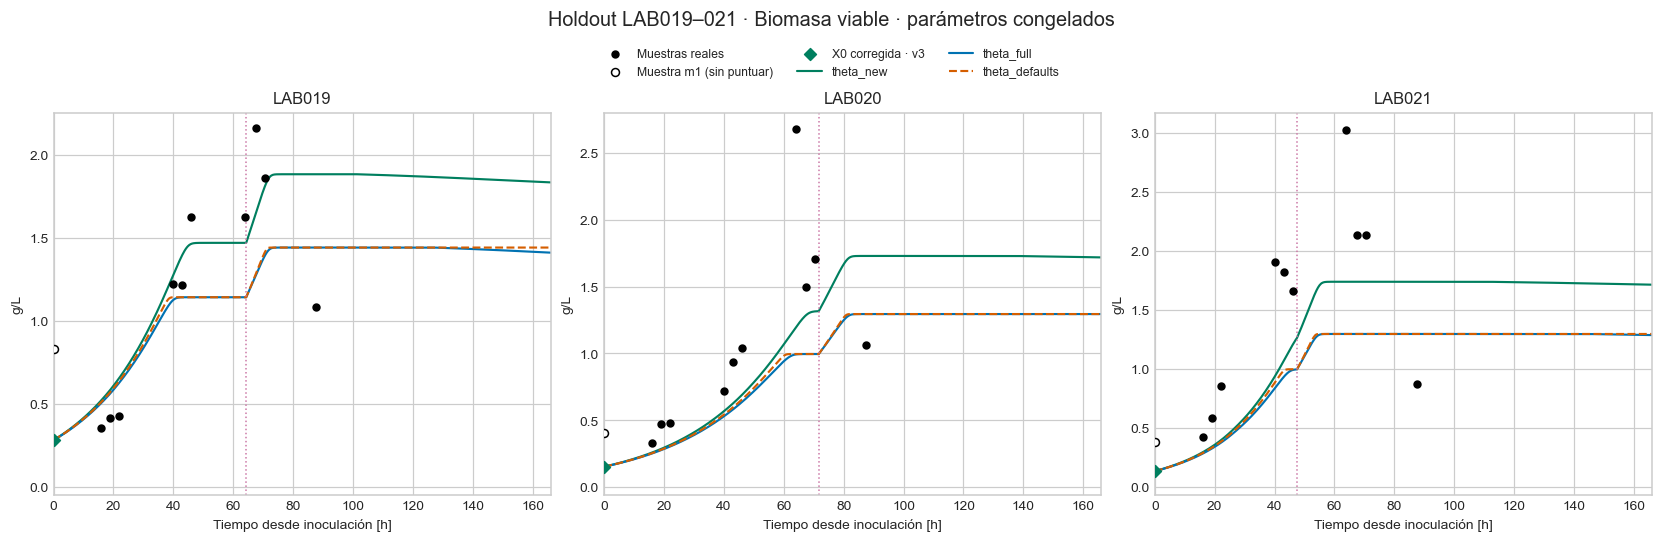

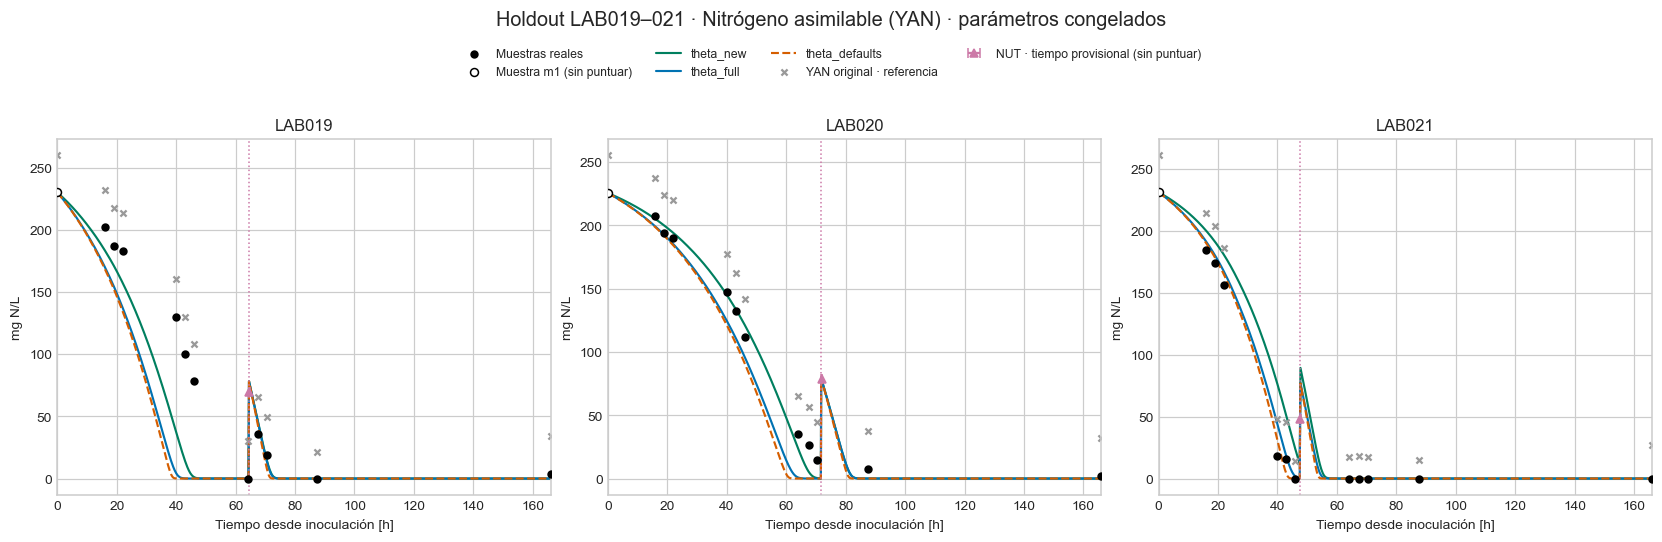

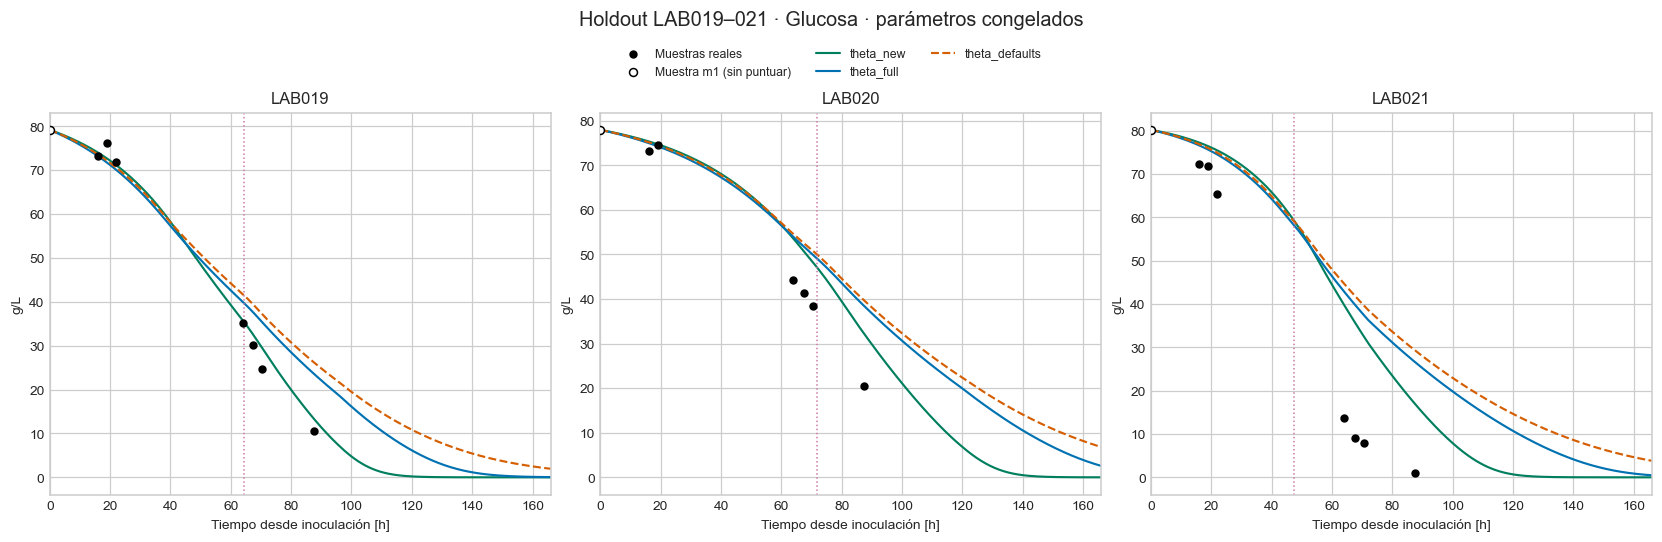

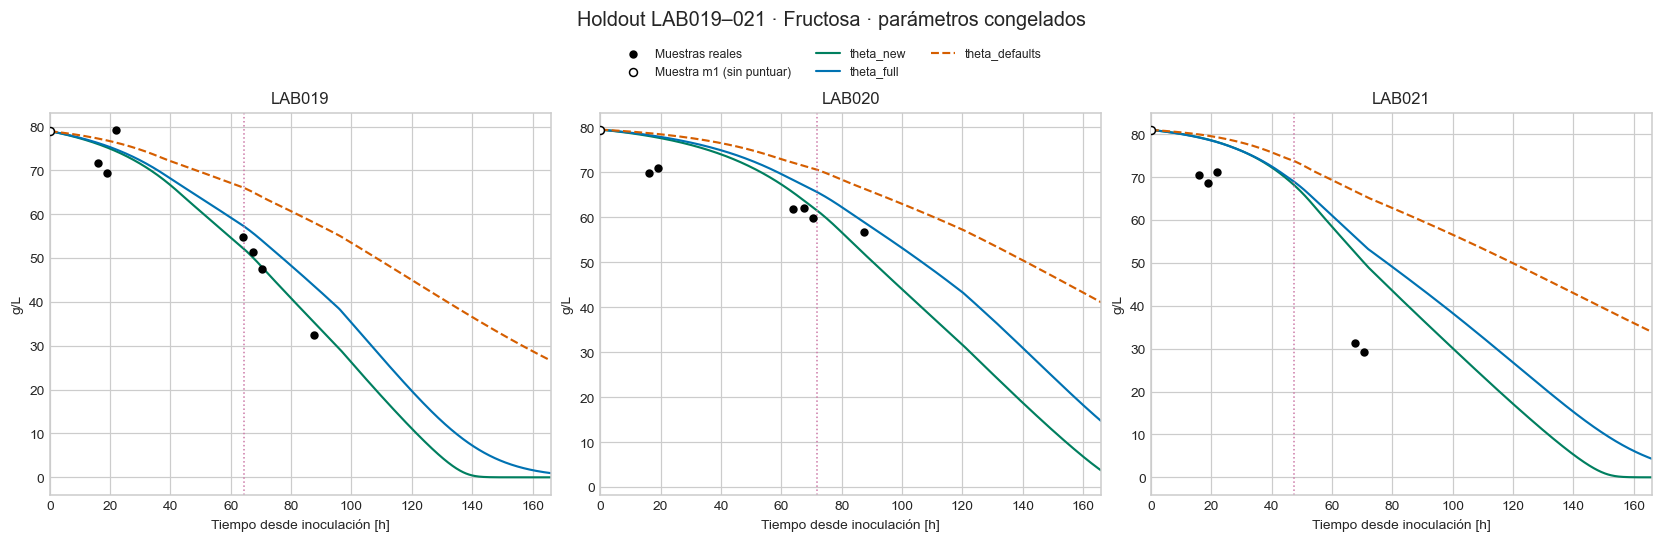

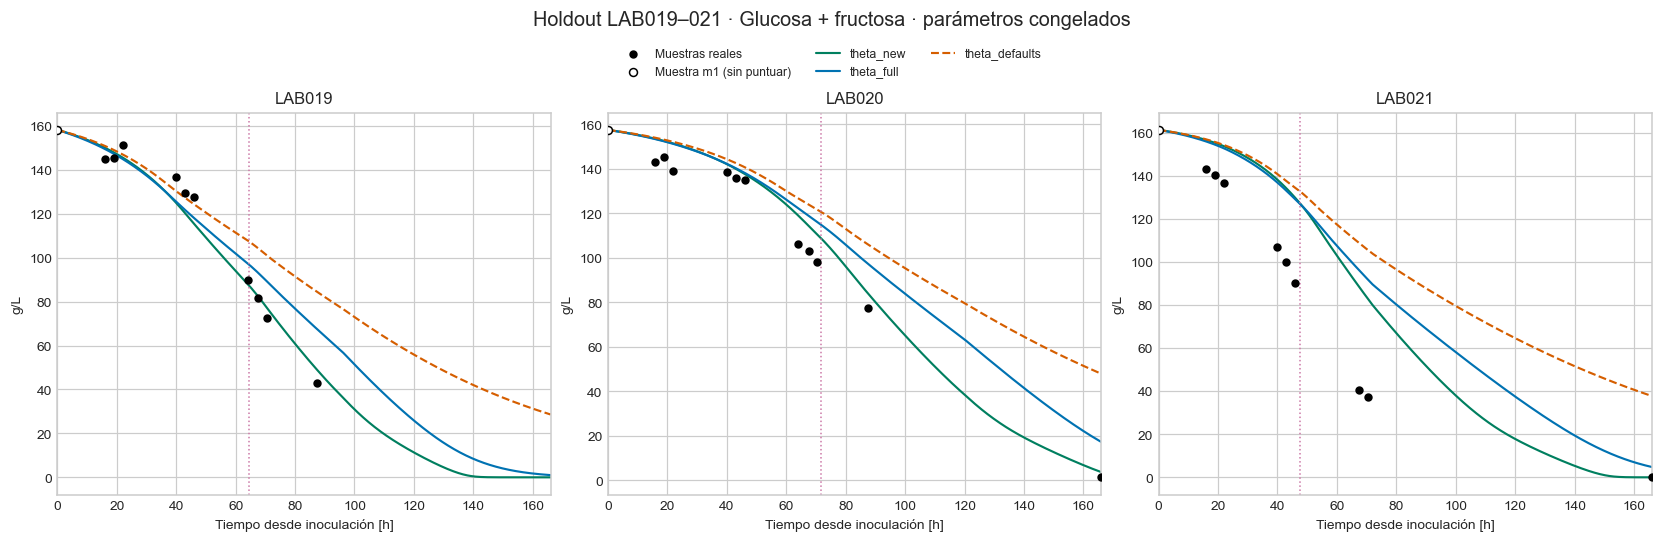

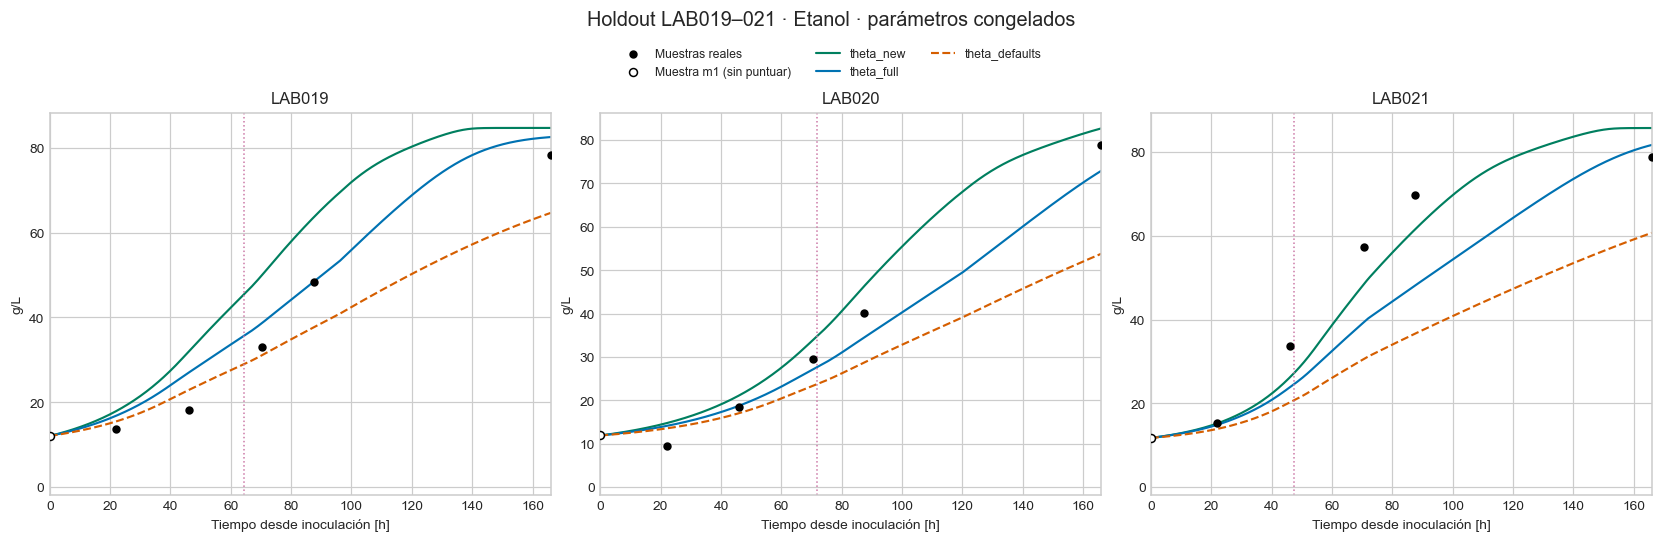

In [13]:
h_colors={'theta_new':'#007F5F','theta_full':'#0072B2','theta_defaults':'#D55E00'}
for state in ['X','N','G','F','GF','E']:
    fig,axes=plt.subplots(1,3,figsize=(15,4.8),layout='constrained')
    for ax,b in zip(axes,h_batches):
        rows=h_qc[h_qc.lab.eq(b.batch)].sort_values('t_h');column=h_state_columns[state]
        valid=rows[column].notna();initial=rows['sample'].eq('1')
        ax.scatter(rows.loc[valid&~initial,'t_h'],rows.loc[valid&~initial,column],c='black',s=20,zorder=5,label='Muestras reales')
        ax.scatter(rows.loc[valid&initial,'t_h'],rows.loc[valid&initial,column],facecolors='white',edgecolors='black',s=27,zorder=6,label='Muestra m1 (sin puntuar)')
        if state=='X':
            ax.scatter([0],[h_initials[b.batch]['X']],marker='D',color='#007F5F',s=30,zorder=7,label='X0 corregida · v3')
        factor=1000 if state=='N' else 1
        for label in H_VECTORS:
            pred=h_predictions[label,b.batch]
            ax.plot(pred.index,pred[state]*factor,color=h_colors[label],lw=1.4,
                ls='--' if label=='theta_defaults' else '-',label=label)
        if state=='N':
            ax.scatter(rows.t_h,rows.YAN_original_mg_l,marker='x',c='#999999',s=16,zorder=2,label='YAN original · referencia')
            nut=h_nut_points[h_nut_points.lab.eq(b.batch)].iloc[0]
            ax.errorbar([nut.t_h],[nut.YAN_mg_l],xerr=[[nut.t_h-nut.time_lower_h],[nut.time_upper_h-nut.t_h]],
                fmt='^',color='#CC79A7',ms=5,capsize=3,zorder=6,label='NUT · tiempo provisional (sin puntuar)')
        for t,a in b.pulses['N']:ax.axvline(t,color='#CC79A7',ls=':',lw=1)
        ax.set(title=b.batch,xlabel='Tiempo desde inoculación [h]',ylabel='mg N/L' if state=='N' else 'g/L',xlim=(0,b.time[-1]))
        lo,hi=ax.get_ylim();ax.set_ylim(min(lo,-.02*max(hi,1)),hi)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.suptitle(f'Holdout LAB019–021 · {LABELS[state]} · parámetros congelados',y=.995,fontsize=13)
    fig.get_layout_engine().set(rect=(0,0,1,.80 if state=='N' else .85))
    fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.945),ncol=4 if state=='N' else 3,frameon=False,fontsize=8)
    plt.show();plt.close(fig)

### 9.3 Conclusiones del holdout

La transferencia a estos tres LAB se distingue del ajuste de LAB004–009. Se conserva theta_new aunque otro vector tenga menor error externo; no se utiliza esta evaluación para seleccionar nuevos parámetros o modificar entradas. Las condiciones iniciales corregidas previamente en v3, la corrección previa de YAN y los horarios son supuestos de entrada explícitos: una discrepancia no permite atribuir por sí sola todo el error a las ecuaciones.

In [14]:
h_lines=[]
for scope in ['core7','focus5']:
    scores=h_summary[(h_summary.lab=='TODOS')&h_summary.variables.eq(scope)].set_index('theta').WRMSE
    ranking=scores.sort_values()
    h_lines.append(f'- **{scope}:** WRMSE theta_new **{scores["theta_new"]:.3f}**, '
        f'theta_full **{scores["theta_full"]:.3f}**, theta_defaults **{scores["theta_defaults"]:.3f}**. Menor en esta cohorte: **{ranking.index[0]}**.')
    change=100*(scores['theta_new']/scores['theta_full']-1)
    h_lines.append(f'- Cambio de WRMSE de theta_new frente a theta_full en {scope}: **{change:+.1f}%**; negativo indica mejora.')
h_lines += ['- No se recalibró ni seleccionó un nuevo theta con el holdout.',
 '- Se utilizó el backup completo de temperatura, verificado contra el objeto LFS local.',
 '- Se conservan NUT con tiempo provisional en figuras; no se puntúan NUT ni las entradas m1.',
 '- Se reutilizan exactamente los siete estados iniciales archivados y acordados en v3; la observación m1 se conserva por separado.',
 '- Esta ejecución sustituye el holdout anterior, que utilizó por error biomasa m1 cruda y produjo conclusiones inválidas para las condiciones iniciales acordadas.']
display(Markdown(chr(10).join(h_lines)))
assert H_THETA_SNAPSHOT==H_VECTORS
assert H_FROZEN_HASHES=={k:h_sha(path) for k,path in H_FROZEN_PATHS.items()}
assert H_HASHES=={k:h_sha(path) for k,path in H_PATHS.items()}
assert INPUT_HASHES=={k:sha(path) for k,path in INPUTS.items()}
assert protected=={str(path.relative_to(ROOT)):sha(path) for root in protected_roots if root.exists() for path in root.rglob('*') if path.is_file()}
h_report={'created_at':datetime.now(ZoneInfo('America/Santiago')).isoformat(),'experiments':list(H_LABS),
 'initial_conditions_policy':'previously agreed v3 archive; measured m1 retained separately',
 'supersedes_incorrect_raw_m1_holdout':True,'fit_performed':False,'co2_layer_used':False,'previously_explored_cohort':True,
 'source_notebook_sha256':h_sha(OUT/'theta_new.source.ipynb'),'frozen_parameters':H_VECTORS,
 'frozen_file_hashes':H_FROZEN_HASHES,'inputs':{k:{'path':str(path.relative_to(ROOT)),'sha256':H_HASHES[k]} for k,path in H_PATHS.items()},
 'temperature_lfs_oid':H_TEMP_OID,'temperature_audit':h_temperature_audit,'initial_conditions':h_initial_audit,
 'CERO_reference_not_subtracted':h_cero,'YAN_policy':'existing corrected CSV; no second subtraction; raw YAN reference',
 'NUT_provisional_excluded_from_primary_metrics':True,'summary':h_summary.to_dict('records'),
 'metrics':h_metrics.to_dict('records'),'numeric_checks':h_numeric.to_dict('records'),'conclusions':h_lines}
(OUT/'holdout_lab019_021.json').write_text(json.dumps(h_report,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
print('Holdout verificado: 3 LAB, cero ajustes, parámetros y resultados previos intactos. Sin nuevos CSV ni figuras en results.')

- **core7:** WRMSE theta_new **3.282**, theta_full **3.610**, theta_defaults **4.421**. Menor en esta cohorte: **theta_new**.
- Cambio de WRMSE de theta_new frente a theta_full en core7: **-9.1%**; negativo indica mejora.
- **focus5:** WRMSE theta_new **3.955**, theta_full **4.360**, theta_defaults **5.378**. Menor en esta cohorte: **theta_new**.
- Cambio de WRMSE de theta_new frente a theta_full en focus5: **-9.3%**; negativo indica mejora.
- No se recalibró ni seleccionó un nuevo theta con el holdout.
- Se utilizó el backup completo de temperatura, verificado contra el objeto LFS local.
- Se conservan NUT con tiempo provisional en figuras; no se puntúan NUT ni las entradas m1.
- Se reutilizan exactamente los siete estados iniciales archivados y acordados en v3; la observación m1 se conserva por separado.
- Esta ejecución sustituye el holdout anterior, que utilizó por error biomasa m1 cruda y produjo conclusiones inválidas para las condiciones iniciales acordadas.

Holdout verificado: 3 LAB, cero ajustes, parámetros y resultados previos intactos. Sin nuevos CSV ni figuras en results.
